<a href="https://colab.research.google.com/github/CuicuiZhang01/DTSC5082_Group11_Delivery-Delay-Predictor/blob/main/Group11_Delivery_Delay_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Delivery Delay Predictor: Predicting Delivery Risk Before It Happens

## Final Data Science Project

**Team Members:**  
Chiranjeevi Garlapati, Cuicui Zhang, Hemanth Sai Bellam, Sneha Latha Astum

**Faculty Mentor:**  
Clifford Whitworth

**Department:**  
The Anuradha and Vikas Sinha Department of Data Science

## 1. Introduction and Background

Delivery delays are an important operational challenge in logistics and e-commerce. Longer delivery times can reduce customer satisfaction, increase operational costs, and create difficulties in managing delivery resources efficiently.

Delivery time can be influenced by several interacting factors, including traffic conditions, weather, delivery distance, agent characteristics, vehicle type, delivery area, product category, and order timing.

Traditional delivery tracking is often reactive because delivery problems may only become apparent after an order has already experienced a significant delay. Machine learning provides an opportunity to take a more proactive approach by estimating delivery time before completion and identifying deliveries associated with relatively high predicted delivery times.

The purpose of this project is to develop and evaluate machine learning models capable of predicting delivery time using available order, agent, environmental, and location information.

The project also incorporates explainable artificial intelligence using SHAP so that the factors contributing to individual predictions can be understood. The ultimate goal is to translate predictive results into interpretable information that could support proactive delivery-management decisions.

## 2. Research Question and Objectives

### Research Question

**Can machine learning accurately predict delivery time and identify deliveries with relatively high delivery-time risk using order, agent, traffic, weather, and location information?**

### Objectives

The objectives of this study are to:

1. Examine the structure and quality of the delivery dataset.
2. Clean and preprocess the dataset to ensure reliable analysis.
3. Conduct exploratory data analysis to understand distributions, patterns, and relationships between variables.
4. Engineer meaningful features such as delivery distance, pickup waiting time, order hour, and day of week.
5. Develop and compare multiple machine learning regression models for delivery-time prediction.
6. Evaluate the models using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².
7. Optimize the strongest-performing models using cross-validation and hyperparameter tuning.
8. Categorize predicted delivery times into relative Low, Medium, and High delivery-risk levels.
9. Apply SHAP analysis to explain the contribution of important features to model predictions.
10. Translate model predictions into interpretable operational recommendations.
11. Develop a reproducible end-to-end data science workflow.

### Scope and Interpretation of Delivery Risk

The dataset used in this project contains observed delivery duration but does not contain the original promised or scheduled delivery deadline for each order.

Therefore, this project cannot directly determine whether a delivery was officially late.

Instead, the term **delivery risk** refers to relative delivery-time risk. Deliveries with higher predicted delivery durations are considered relatively higher risk compared with other deliveries in the dataset.

This distinction is important because the project's risk categories should not be interpreted as confirmed service-level violations or confirmed late deliveries.

## 3. Environment Setup and Reproducibility

Reproducibility is an important component of the data science process. Recording the software environment and package versions helps ensure that the analysis can be reproduced using the same computational tools.

A fixed random state is also used throughout the project. Machine learning procedures such as train-test splitting, ensemble methods, and neural-network initialization may involve random processes. Using a consistent random seed helps ensure that repeated runs of the notebook produce comparable results.

In [1]:
# ============================================================
# SECTION 3: ENVIRONMENT SETUP
# ============================================================

import sys
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
import shap

# Reduce unnecessary warning messages
warnings.filterwarnings("ignore")

# Random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment successfully loaded!")
print("-" * 55)
print(f"Python Version       : {sys.version.split()[0]}")
print(f"Operating System     : {platform.system()} {platform.release()}")
print(f"Pandas Version       : {pd.__version__}")
print(f"NumPy Version        : {np.__version__}")
print(f"Scikit-learn Version : {sklearn.__version__}")
print(f"XGBoost Version      : {xgboost.__version__}")
print(f"SHAP Version         : {shap.__version__}")
print(f"Random State         : {RANDOM_STATE}")

Environment successfully loaded!
-------------------------------------------------------
Python Version       : 3.13.18
Operating System     : Linux 6.6.159+
Pandas Version       : 2.2.3
NumPy Version        : 2.4.6
Scikit-learn Version : 1.6.1
XGBoost Version      : 3.4.1
SHAP Version         : 0.54.1
Random State         : 42


## 4. Data Acquisition and Dataset Description

### 4.1 Data Source and Source Validation

This project uses the **Amazon Delivery Dataset** published on Kaggle by **Sujal Suthar**.

The dataset contains delivery-level information including:

- delivery-agent age and rating,
- store latitude and longitude,
- drop-off latitude and longitude,
- order date and time,
- pickup time,
- weather conditions,
- traffic conditions,
- vehicle type,
- delivery area,
- product category,
- and observed delivery time.

The dataset contains **43,739 delivery records and 16 variables** in its original form.

### Source Validation

Kaggle provides the dataset as a publicly accessible tabular data source suitable for reproducible data-science analysis. However, the publicly available dataset page does not provide sufficient documentation to independently verify the original operational collection process or confirm that the records represent direct production data from Amazon.

Therefore, this study treats the dataset as a publicly available research dataset labeled as the Amazon Delivery Dataset rather than making claims that it represents verified internal Amazon operational data.

This limitation is considered when interpreting the findings and generalizing results beyond the dataset.

### Data Governance Considerations

The dataset does not contain obvious personally identifiable information such as customer names, addresses, phone numbers, or email addresses. The analysis focuses on operational and delivery-related variables.

The original raw dataset is preserved separately in the notebook as `df_raw`, while all cleaning and transformation procedures are applied to a working copy. This preserves data provenance and makes the preprocessing process reproducible.

In [3]:
# ============================================================
# SECTION 4: DATA ACQUISITION
# ============================================================

# Load the original dataset
df_raw = pd.read_csv("data/amazon_delivery.csv")

# Create a working copy so the original data remains unchanged
df = df_raw.copy()

print("Dataset loaded successfully!")
print("-" * 55)
print(f"Number of rows    : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]}")
print(f"Total data points : {df.shape[0] * df.shape[1]:,}")

# Display the first five records
df.head()

Dataset loaded successfully!
-------------------------------------------------------
Number of rows    : 43,739
Number of columns : 16
Total data points : 699,824


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


## 5. Initial Data Audit

Before cleaning or transforming the dataset, an initial data audit is performed to understand its structure and identify potential data-quality problems.

The audit examines:

1. Dataset dimensions
2. Column names
3. Data types
4. Example observations
5. Missing values
6. Duplicate records
7. Numerical summary statistics
8. Categorical variable values

This stage is important because machine learning models depend on the quality and consistency of their input data. Problems such as missing values, incorrect data types, inconsistent category labels, duplicate observations, or invalid values should be identified before model development.

In [4]:
# ============================================================
# 5.1 DATASET STRUCTURE
# ============================================================

print("COLUMN NAMES")
print("=" * 55)

for number, column in enumerate(df.columns, start=1):
    print(f"{number:2}. {column}")

print("\nDATASET INFORMATION")
print("=" * 55)

df.info()

COLUMN NAMES
 1. Order_ID
 2. Agent_Age
 3. Agent_Rating
 4. Store_Latitude
 5. Store_Longitude
 6. Drop_Latitude
 7. Drop_Longitude
 8. Order_Date
 9. Order_Time
10. Pickup_Time
11. Weather
12. Traffic
13. Vehicle
14. Area
15. Delivery_Time
16. Category

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43739 entries, 0 to 43738
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         43739 non-null  object 
 1   Agent_Age        43739 non-null  int64  
 2   Agent_Rating     43685 non-null  float64
 3   Store_Latitude   43739 non-null  float64
 4   Store_Longitude  43739 non-null  float64
 5   Drop_Latitude    43739 non-null  float64
 6   Drop_Longitude   43739 non-null  float64
 7   Order_Date       43739 non-null  object 
 8   Order_Time       43739 non-null  object 
 9   Pickup_Time      43739 non-null  object 
 10  Weather          43648 non-null  object 
 11  Traffic     

In [5]:
# ============================================================
# 5.2 MISSING VALUE AUDIT
# ============================================================

missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_values = missing_values[
    missing_values["Missing_Count"] > 0
].sort_values(
    "Missing_Count",
    ascending=False
)

print("MISSING VALUE SUMMARY")
print("=" * 55)

if len(missing_values) == 0:
    print("No missing values detected.")
else:
    display(missing_values)

MISSING VALUE SUMMARY


,Missing_Count,Missing_Percentage
Weather,91,0.21
Agent_Rating,54,0.12


In [6]:
# ============================================================
# 5.3 DUPLICATE RECORD AUDIT
# ============================================================

duplicate_count = df.duplicated().sum()
duplicate_percentage = duplicate_count / len(df) * 100

print("DUPLICATE RECORD SUMMARY")
print("=" * 55)
print(f"Duplicate rows       : {duplicate_count:,}")
print(f"Duplicate percentage : {duplicate_percentage:.2f}%")

DUPLICATE RECORD SUMMARY
Duplicate rows       : 0
Duplicate percentage : 0.00%


In [7]:
# ============================================================
# 5.4 NUMERICAL VARIABLE SUMMARY
# ============================================================

numerical_summary = df.describe().T

numerical_summary

,count,mean,std,min,25%,50%,75%,max
Agent_Age,43739.0,29.567137,5.815155,15.000000,25.000000,30.000000,35.000000,50.000000
Agent_Rating,43685.0,4.633780,0.334716,1.000000,4.500000,4.700000,4.900000,6.000000
Store_Latitude,43739.0,17.210960,7.764225,-30.902872,12.933298,18.551440,22.732225,30.914057
Store_Longitude,43739.0,70.661177,21.475005,-88.366217,73.170283,75.898497,78.045359,88.433452
Drop_Latitude,43739.0,17.459031,7.342950,0.010000,12.985996,18.633626,22.785049,31.054057
Drop_Longitude,43739.0,70.821842,21.153148,0.010000,73.280000,76.002574,78.104095,88.563452
Delivery_Time,43739.0,124.905645,51.915451,10.000000,90.000000,125.000000,160.000000,270.000000


### Initial Data Audit Findings

The raw dataset contains **43,739 delivery records and 16 variables**, providing a sufficiently large sample for exploratory analysis and machine learning.

The initial audit identified the following data-quality characteristics:

- The dataset contains **no fully duplicated rows**.
- `Weather` contains **91 missing values (0.21%)**.
- `Agent_Rating` contains **54 missing values (0.12%)**.
- Most variables are complete, indicating that the overall level of missing data is relatively low.
- `Delivery_Time`, the prediction target, ranges from **10 to 270 minutes**, with a median of approximately **125 minutes**.
- `Agent_Age` ranges from **15 to 50 years**, which suggests that unusually low age values should be investigated before modeling.
- `Agent_Rating` ranges from **1.0 to 6.0**. Since rating scales commonly have an upper limit of 5, values above 5 require further validation.
- Several geographic coordinate variables contain unusual values, including zero or negative coordinates. These observations require investigation before calculating delivery distance.
- Date and time variables are currently stored as text and must be converted to appropriate datetime representations before feature engineering.

These observations do not automatically imply that records should be removed. Each issue will be examined systematically during the data-cleaning stage before any transformation is applied.

### 5.5 Categorical Variable Audit

Categorical variables are inspected to identify the number of unique categories, class imbalance, spelling inconsistencies, whitespace problems, and placeholder values that may represent missing data.

This is particularly important before machine learning because inconsistent labels such as `"Low"` and `"Low "` would otherwise be treated as separate categories during encoding.

In [8]:
# ============================================================
# 5.5 CATEGORICAL VARIABLE AUDIT
# ============================================================

categorical_columns = [
    "Weather",
    "Traffic",
    "Vehicle",
    "Area",
    "Category"
]

for column in categorical_columns:
    print("\n" + "=" * 60)
    print(f"{column.upper()} - VALUE COUNTS")
    print("=" * 60)

    display(
        df[column]
        .value_counts(dropna=False)
        .rename("Count")
        .to_frame()
    )


WEATHER - VALUE COUNTS


,Count
Weather,
Fog,7440
Stormy,7374
Cloudy,7288
Sandstorms,7245
Windy,7223
Sunny,7078
NaN,91



TRAFFIC - VALUE COUNTS


,Count
Traffic,
Low,14999
Jam,13725
Medium,10628
High,4296
NaN,91



VEHICLE - VALUE COUNTS


,Count
Vehicle,
motorcycle,25527
scooter,14639
van,3558
bicycle,15



AREA - VALUE COUNTS


,Count
Area,
Metropolitian,32698
Urban,9751
Other,1138
Semi-Urban,152



CATEGORY - VALUE COUNTS


,Count
Category,
Electronics,2849
Books,2824
Jewelry,2802
Toys,2781
Skincare,2772
Snacks,2770
Outdoors,2747
Apparel,2726
Sports,2719


### 5.6 String Formatting and Whitespace Audit

Categorical text may contain leading or trailing whitespace that is not visually obvious when displayed in a table.

For example, `"High"` and `"High "` appear similar to a user but are treated as different strings by Python. Such inconsistencies can create unnecessary categories and negatively affect preprocessing.

Therefore, all text-based columns are examined for leading or trailing whitespace before cleaning.

In [9]:
# ============================================================
# 5.6 WHITESPACE AUDIT
# ============================================================

text_columns = df.select_dtypes(include="object").columns

whitespace_results = []

for column in text_columns:
    non_null_values = df[column].dropna().astype(str)

    whitespace_count = (
        non_null_values != non_null_values.str.strip()
    ).sum()

    whitespace_results.append({
        "Column": column,
        "Rows_With_Whitespace": whitespace_count
    })

whitespace_audit = pd.DataFrame(whitespace_results)

display(
    whitespace_audit[
        whitespace_audit["Rows_With_Whitespace"] > 0
    ].reset_index(drop=True)
)

,Column,Rows_With_Whitespace
0,Order_Time,91
1,Traffic,43739
2,Vehicle,40181
3,Area,42601


### 5.7 Placeholder Missing-Value Audit

Missing information is not always stored as a true null value. Some datasets contain textual placeholders such as `"NaN"`, `"NA"`, `"N/A"`, or empty strings.

These values must be detected because machine learning preprocessing may otherwise interpret them as legitimate categories rather than missing observations.

In [10]:
# ============================================================
# 5.7 PLACEHOLDER MISSING-VALUE AUDIT
# ============================================================

missing_tokens = ["NaN", "nan", "NA", "N/A", "NULL", "None", ""]

placeholder_results = []

for column in text_columns:
    cleaned_text = df[column].astype(str).str.strip()

    placeholder_count = cleaned_text.isin(missing_tokens).sum()

    if placeholder_count > 0:
        placeholder_results.append({
            "Column": column,
            "Placeholder_Missing_Count": placeholder_count
        })

placeholder_audit = pd.DataFrame(placeholder_results)

display(placeholder_audit)

,Column,Placeholder_Missing_Count
0,Order_Time,91
1,Weather,91
2,Traffic,91


### 5.8 Date and Time Validation

The dataset contains `Order_Date`, `Order_Time`, and `Pickup_Time`. These variables are currently represented as text.

Before deriving temporal features, the values must be checked to ensure they can be converted successfully into valid dates and times.

Validating these fields before conversion prevents malformed timestamps from silently entering the feature-engineering process.

In [11]:
# ============================================================
# 5.8 DATE AND TIME AUDIT
# ============================================================

# Test conversion without modifying the original columns
order_date_test = pd.to_datetime(
    df["Order_Date"],
    errors="coerce"
)

order_time_test = pd.to_datetime(
    df["Order_Time"].astype(str).str.strip(),
    format="%H:%M:%S",
    errors="coerce"
)

pickup_time_test = pd.to_datetime(
    df["Pickup_Time"].astype(str).str.strip(),
    format="%H:%M:%S",
    errors="coerce"
)

date_time_audit = pd.DataFrame({
    "Variable": [
        "Order_Date",
        "Order_Time",
        "Pickup_Time"
    ],
    "Invalid_or_Missing_After_Conversion": [
        order_date_test.isna().sum(),
        order_time_test.isna().sum(),
        pickup_time_test.isna().sum()
    ]
})

display(date_time_audit)

print(
    "Order date range:",
    order_date_test.min().date(),
    "to",
    order_date_test.max().date()
)

,Variable,Invalid_or_Missing_After_Conversion
0,Order_Date,0
1,Order_Time,91
2,Pickup_Time,0


Order date range: 2022-02-11 to 2022-04-06


### 5.9 Numerical Validity Checks

Summary statistics can reveal values that are mathematically valid but potentially unrealistic within the context of the dataset.

The following checks investigate:

- unusually young delivery-agent ages,
- ratings outside the expected 1–5 range,
- zero geographic coordinates,
- negative coordinates,
- coordinates outside globally valid latitude and longitude ranges.

These checks are exploratory. Records are not removed until the likely cause and appropriate treatment have been considered.

In [12]:
# ============================================================
# 5.9 NUMERICAL VALIDITY AUDIT
# ============================================================

validity_checks = pd.DataFrame({
    "Potential_Issue": [
        "Agent age below 18",
        "Agent rating below 1",
        "Agent rating above 5",
        "Store latitude equal to 0",
        "Store longitude equal to 0",
        "Drop latitude equal to 0",
        "Drop longitude equal to 0",
        "Store latitude outside [-90, 90]",
        "Drop latitude outside [-90, 90]",
        "Store longitude outside [-180, 180]",
        "Drop longitude outside [-180, 180]"
    ],

    "Count": [
        (df["Agent_Age"] < 18).sum(),
        (df["Agent_Rating"] < 1).sum(),
        (df["Agent_Rating"] > 5).sum(),
        (df["Store_Latitude"] == 0).sum(),
        (df["Store_Longitude"] == 0).sum(),
        (df["Drop_Latitude"] == 0).sum(),
        (df["Drop_Longitude"] == 0).sum(),
        (
            (df["Store_Latitude"] < -90) |
            (df["Store_Latitude"] > 90)
        ).sum(),
        (
            (df["Drop_Latitude"] < -90) |
            (df["Drop_Latitude"] > 90)
        ).sum(),
        (
            (df["Store_Longitude"] < -180) |
            (df["Store_Longitude"] > 180)
        ).sum(),
        (
            (df["Drop_Longitude"] < -180) |
            (df["Drop_Longitude"] > 180)
        ).sum()
    ]
})

display(validity_checks)

,Potential_Issue,Count
0,Agent age below 18,38
1,Agent rating below 1,0
2,Agent rating above 5,53
3,Store latitude equal to 0,3505
4,Store longitude equal to 0,3505
5,Drop latitude equal to 0,0
6,Drop longitude equal to 0,0
7,"Store latitude outside [-90, 90]",0
8,"Drop latitude outside [-90, 90]",0
9,"Store longitude outside [-180, 180]",0


### 5.10 Initial Data Audit Interpretation

The initial audit identified several data-quality issues that require treatment before exploratory analysis and model development.

#### Missing Data

The dataset contains relatively little missing information overall. `Weather` contains 91 true missing values and `Agent_Rating` contains 54 missing values.

In addition, some missing information is represented using textual placeholders rather than true null values. Specifically, 91 observations in `Order_Time` and 91 observations in `Traffic` contain `"NaN"`-type placeholder values.

These placeholder values must first be converted into proper missing values so that they can be handled consistently.

#### String Formatting

Substantial leading or trailing whitespace was detected in several categorical columns. All records in `Traffic` contain whitespace, while most values in `Vehicle` and `Area` are also affected.

Whitespace does not change the human-readable meaning of a category but can cause Python and machine learning algorithms to interpret otherwise identical labels as different values. These strings will therefore be standardized using whitespace removal.

#### Date and Time Variables

`Order_Date` and `Pickup_Time` can be successfully converted into valid temporal formats. However, 91 `Order_Time` observations cannot be converted because they contain placeholder missing values.

The available data span from February 11, 2022 through April 6, 2022.

#### Numerical Validity

Several potentially invalid numerical observations were identified:

- 38 delivery agents have an age below 18.
- 53 agent ratings are greater than 5.
- 3,505 observations contain store coordinates equal to `(0, 0)`.

Although the zero coordinates are globally valid geographic coordinates, they are unlikely to represent actual store locations in the context of this delivery dataset. These records require further investigation before geographic features such as delivery distance are calculated.

No latitude or longitude values exceed globally valid coordinate boundaries.

Overall, the audit demonstrates that the dataset is largely complete but requires systematic cleaning of missing-value representations, text formatting, temporal variables, and potentially invalid numerical values.

## 6. Data Cleaning and Quality Control

Data cleaning is performed before exploratory data analysis and machine learning to ensure that inconsistent or invalid information does not negatively affect subsequent results.

The cleaning process includes:

1. Preserving the original raw dataset.
2. Removing leading and trailing whitespace from text variables.
3. Converting textual missing-value placeholders into true null values.
4. Converting date and time variables into appropriate formats.
5. Investigating potentially invalid agent ages and ratings.
6. Investigating invalid or placeholder geographic coordinates.
7. Handling missing values using appropriate methods.
8. Verifying the cleaned dataset after all transformations.

Cleaning decisions are based on the meaning of each variable rather than applying a single rule to every column.

In [13]:
# ============================================================
# SECTION 6: DATA CLEANING
# ============================================================

# Start cleaning from a fresh copy of the untouched raw dataset
df = df_raw.copy()

print("Cleaning dataset initialized.")
print(f"Starting rows    : {df.shape[0]:,}")
print(f"Starting columns : {df.shape[1]}")

Cleaning dataset initialized.
Starting rows    : 43,739
Starting columns : 16


### 6.1 Standardizing Text Variables

Leading and trailing whitespace is removed from all text-based variables.

This operation does not change the semantic meaning of the values. Instead, it ensures that equivalent categories are represented consistently. For example, `"Low "` and `"Low"` should represent the same traffic category rather than being treated as separate values.

In [14]:
# ============================================================
# 6.1 STANDARDIZE TEXT VALUES
# ============================================================

text_columns = df.select_dtypes(include="object").columns

# Remove leading and trailing whitespace
for column in text_columns:
    df[column] = df[column].str.strip()

# Standardize inconsistent category spelling
df["Area"] = df["Area"].replace({
    "Metropolitian": "Metropolitan"
})

print("Text values standardized successfully.")

Text values standardized successfully.


In [15]:
# Verify standardized Area categories

display(
    df["Area"]
    .value_counts()
    .rename("Count")
    .to_frame()
)

,Count
Area,
Metropolitan,32698
Urban,9751
Other,1138
Semi-Urban,152


The inconsistent area label `"Metropolitian"` is also standardized to `"Metropolitan"` so that the category is represented using consistent spelling throughout the analysis.

In [16]:
# Verify whitespace cleaning

whitespace_after = []

for column in text_columns:
    non_null_values = df[column].dropna().astype(str)

    whitespace_count = (
        non_null_values != non_null_values.str.strip()
    ).sum()

    whitespace_after.append({
        "Column": column,
        "Rows_With_Whitespace": whitespace_count
    })

display(pd.DataFrame(whitespace_after))

,Column,Rows_With_Whitespace
0,Order_ID,0
1,Order_Date,0
2,Order_Time,0
3,Pickup_Time,0
4,Weather,0
5,Traffic,0
6,Vehicle,0
7,Area,0
8,Category,0


### 6.2 Standardizing Missing-Value Representations

Some missing information is stored as text rather than as a true null value. Textual placeholders such as `"NaN"`, `"NA"`, `"N/A"`, `"NULL"`, and empty strings are converted to `NaN`.

This ensures that missing data can be detected and treated consistently using standard pandas and machine learning procedures.

In [17]:
# ============================================================
# 6.2 STANDARDIZE MISSING VALUES
# ============================================================

missing_tokens = [
    "NaN",
    "nan",
    "NA",
    "N/A",
    "NULL",
    "None",
    ""
]

df = df.replace(missing_tokens, np.nan)

print("Placeholder missing values converted to true NaN values.")

Placeholder missing values converted to true NaN values.


In [18]:
missing_after_standardization = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().sum() / len(df) * 100
    ).round(2)
})

missing_after_standardization = (
    missing_after_standardization[
        missing_after_standardization["Missing_Count"] > 0
    ]
    .sort_values("Missing_Count", ascending=False)
)

display(missing_after_standardization)

,Missing_Count,Missing_Percentage
Order_Time,91,0.21
Weather,91,0.21
Traffic,91,0.21
Agent_Rating,54,0.12


### 6.3 Converting Date and Time Variables

Temporal variables are converted from text into structured date/time representations.

`Order_Date` is converted into a date variable, while `Order_Time` and `Pickup_Time` are converted into time-compatible datetime values.

Converting these variables enables later feature engineering such as:

- order hour,
- day of week,
- weekend indicator,
- pickup waiting time.

Missing order times remain missing rather than being artificially assigned a time at this stage.

In [19]:
# ============================================================
# 6.3 DATE AND TIME CONVERSION
# ============================================================

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    errors="coerce"
)

df["Order_Time"] = pd.to_datetime(
    df["Order_Time"],
    format="%H:%M:%S",
    errors="coerce"
)

df["Pickup_Time"] = pd.to_datetime(
    df["Pickup_Time"],
    format="%H:%M:%S",
    errors="coerce"
)

print("Date and time conversion completed.")

print("\nData types:")
print(df[[
    "Order_Date",
    "Order_Time",
    "Pickup_Time"
]].dtypes)

Date and time conversion completed.

Data types:
Order_Date     datetime64[ns]
Order_Time     datetime64[ns]
Pickup_Time    datetime64[ns]
dtype: object


### 6.4 Investigation of Potentially Invalid Agent Values

The initial audit identified agent ages below 18 and ratings above 5.

Before deciding whether these observations should be removed, replaced, or retained, their exact values and frequencies are examined.

This avoids making arbitrary cleaning decisions based only on minimum and maximum values.

In [20]:
# ============================================================
# 6.4 INVESTIGATE AGENT AGE AND RATING ANOMALIES
# ============================================================

print("AGENT AGES BELOW 18")
print("=" * 50)

display(
    df.loc[
        df["Agent_Age"] < 18,
        "Agent_Age"
    ]
    .value_counts()
    .sort_index()
    .rename("Count")
    .to_frame()
)

print("\nAGENT RATINGS ABOVE 5")
print("=" * 50)

display(
    df.loc[
        df["Agent_Rating"] > 5,
        "Agent_Rating"
    ]
    .value_counts()
    .sort_index()
    .rename("Count")
    .to_frame()
)

AGENT AGES BELOW 18


,Count
Agent_Age,
15,38



AGENT RATINGS ABOVE 5


,Count
Agent_Rating,
6.0,53


### 6.5 Investigation of Geographic Coordinate Anomalies

The initial audit identified 3,505 observations with store latitude and longitude values equal to zero.

Although `(0, 0)` is technically a valid geographic coordinate, it is unlikely to represent an actual store location in the context of this dataset.

These records are therefore examined before geographic features such as delivery distance are calculated.

In [21]:
# ============================================================
# 6.5 INVESTIGATE ZERO STORE COORDINATES
# ============================================================

zero_store_coordinates = df[
    (df["Store_Latitude"] == 0) &
    (df["Store_Longitude"] == 0)
]

print(
    f"Rows with store coordinates (0, 0): "
    f"{len(zero_store_coordinates):,}"
)

display(
    zero_store_coordinates[
        [
            "Store_Latitude",
            "Store_Longitude",
            "Drop_Latitude",
            "Drop_Longitude",
            "Area",
            "Delivery_Time"
        ]
    ].head(15)
)

Rows with store coordinates (0, 0): 3,505


,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Area,Delivery_Time
33,0.0,0.0,0.11,0.11,Urban,35
51,0.0,0.0,0.03,0.03,Metropolitan,75
56,0.0,0.0,0.08,0.08,Semi-Urban,245
58,0.0,0.0,0.06,0.06,Metropolitan,150
66,0.0,0.0,0.02,0.02,Metropolitan,15
67,0.0,0.0,0.04,0.04,Urban,80
71,0.0,0.0,0.08,0.08,Urban,75
72,0.0,0.0,0.02,0.02,Metropolitan,85
74,0.0,0.0,0.05,0.05,Metropolitan,135
79,0.0,0.0,0.11,0.11,Metropolitan,125


In [22]:
# Summary of drop-off coordinates associated with zero store coordinates

zero_coordinate_summary = zero_store_coordinates[
    [
        "Drop_Latitude",
        "Drop_Longitude"
    ]
].describe().T

display(zero_coordinate_summary)

,count,mean,std,min,25%,50%,75%,max
Drop_Latitude,3505.0,0.063121,0.036054,0.01,0.03,0.06,0.09,0.13
Drop_Longitude,3505.0,0.063121,0.036054,0.01,0.03,0.06,0.09,0.13


### 6.6 Relationship Between Agent Anomalies and Missing Operational Data

The potentially invalid agent values may represent corrupted or placeholder records rather than independent data-quality problems.

To investigate this possibility, records containing an agent age below 18 or an agent rating above 5 are compared with records containing missing order time, weather, and traffic information.

If these problems occur in the same observations, removing those records may be more appropriate than independently imputing several unreliable values.

In [23]:
# ============================================================
# 6.6 INVESTIGATE OVERLAP OF DATA QUALITY ISSUES
# ============================================================

agent_anomaly_mask = (
    (df["Agent_Age"] < 18) |
    (df["Agent_Rating"] > 5)
)

anomaly_overlap = pd.DataFrame({
    "Condition": [
        "Agent age < 18 or rating > 5",
        "Anomaly rows with missing Order_Time",
        "Anomaly rows with missing Weather",
        "Anomaly rows with missing Traffic"
    ],

    "Count": [
        agent_anomaly_mask.sum(),

        (
            agent_anomaly_mask &
            df["Order_Time"].isna()
        ).sum(),

        (
            agent_anomaly_mask &
            df["Weather"].isna()
        ).sum(),

        (
            agent_anomaly_mask &
            df["Traffic"].isna()
        ).sum()
    ]
})

display(anomaly_overlap)

,Condition,Count
0,Agent age < 18 or rating > 5,91
1,Anomaly rows with missing Order_Time,91
2,Anomaly rows with missing Weather,91
3,Anomaly rows with missing Traffic,91


### 6.7 Removal of Internally Inconsistent Records

The investigation showed that all records containing an agent age below 18 or an agent rating above 5 also contain missing values for order time, weather, and traffic.

These observations therefore contain multiple simultaneous data-quality problems rather than a single isolated missing feature.

Because only a small proportion of the dataset is affected and several important predictor values are unreliable within the same records, these observations are removed rather than extensively imputed.

This approach avoids introducing artificial values into records that already contain multiple inconsistencies.

In [24]:
# ============================================================
# 6.7 REMOVE INTERNALLY INCONSISTENT RECORDS
# ============================================================

rows_before = len(df)

df = df.loc[~agent_anomaly_mask].copy()

rows_after = len(df)

print("Invalid agent records removed.")
print("-" * 55)
print(f"Rows before cleaning : {rows_before:,}")
print(f"Rows removed         : {rows_before - rows_after:,}")
print(f"Rows remaining       : {rows_after:,}")

Invalid agent records removed.
-------------------------------------------------------
Rows before cleaning : 43,739
Rows removed         : 91
Rows remaining       : 43,648


In [25]:
# ============================================================
# MISSING VALUES AFTER REMOVING CORRUPTED RECORDS
# ============================================================

missing_after_record_removal = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().sum() / len(df) * 100
    ).round(2)
})

display(
    missing_after_record_removal[
        missing_after_record_removal["Missing_Count"] > 0
    ]
)

,Missing_Count,Missing_Percentage
Agent_Rating,54,0.12


### 6.8 Geographic Sign Consistency

Some store coordinates contain negative latitude values. The relationship between these values and their corresponding drop-off coordinates is examined before correction.

If the absolute value of the store coordinate produces the expected small geographic displacement between the store and destination, the negative sign is likely a data-entry or encoding error rather than a genuine store location.

In [26]:
# ============================================================
# 6.8 INVESTIGATE NEGATIVE STORE COORDINATES
# ============================================================

negative_store_latitude = df["Store_Latitude"] < 0
negative_store_longitude = df["Store_Longitude"] < 0

print("Negative coordinate summary")
print("=" * 55)
print(
    f"Negative store latitudes  : "
    f"{negative_store_latitude.sum():,}"
)
print(
    f"Negative store longitudes : "
    f"{negative_store_longitude.sum():,}"
)

negative_coordinate_sample = df.loc[
    negative_store_latitude | negative_store_longitude,
    [
        "Store_Latitude",
        "Store_Longitude",
        "Drop_Latitude",
        "Drop_Longitude"
    ]
].copy()

display(negative_coordinate_sample.head(10))

Negative coordinate summary
Negative store latitudes  : 156
Negative store longitudes : 0


,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude
90,-27.163303,78.057044,27.233303,78.127044
275,-27.165108,78.015053,27.225108,78.075053
1045,-15.546594,73.760431,15.606594,73.820431
1705,-23.230791,77.437020,23.250791,77.457020
1893,-22.539129,88.365507,22.549129,88.375507
2015,-15.157944,73.950889,15.197944,73.990889
2052,-9.959778,76.296106,9.969778,76.306106
2112,-15.513150,73.783460,15.563150,73.833460
2202,-15.576683,73.755750,15.646683,73.825750
2526,-30.902872,75.826808,30.972872,75.896808


In [27]:
# Test the coordinate relationship after removing negative signs

coordinate_test = negative_coordinate_sample.copy()

coordinate_test["Corrected_Store_Latitude"] = (
    coordinate_test["Store_Latitude"].abs()
)

coordinate_test["Corrected_Store_Longitude"] = (
    coordinate_test["Store_Longitude"].abs()
)

coordinate_test["Latitude_Difference"] = (
    coordinate_test["Drop_Latitude"] -
    coordinate_test["Corrected_Store_Latitude"]
)

coordinate_test["Longitude_Difference"] = (
    coordinate_test["Drop_Longitude"] -
    coordinate_test["Corrected_Store_Longitude"]
)

display(
    coordinate_test[
        [
            "Latitude_Difference",
            "Longitude_Difference"
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Latitude_Difference,156.0,0.061923,0.035435,0.01,0.03,0.06,0.09,0.14
Longitude_Difference,156.0,0.061923,0.035435,0.01,0.03,0.06,0.09,0.14


### 6.9 Correction of Coordinate Sign Errors

The negative store-coordinate observations follow the same small store-to-destination displacement pattern as the rest of the dataset after their signs are corrected.

Therefore, negative store latitude and longitude values are converted to their absolute values.

This correction preserves the observations while restoring geographic consistency.

In [28]:
# ============================================================
# 6.9 CORRECT NEGATIVE COORDINATE SIGNS
# ============================================================

df["Store_Latitude"] = df["Store_Latitude"].abs()
df["Store_Longitude"] = df["Store_Longitude"].abs()

print("Negative coordinate signs corrected.")

print(
    "Remaining negative store latitudes:",
    (df["Store_Latitude"] < 0).sum()
)

print(
    "Remaining negative store longitudes:",
    (df["Store_Longitude"] < 0).sum()
)

Negative coordinate signs corrected.
Remaining negative store latitudes: 0
Remaining negative store longitudes: 0


### 6.10 Treatment of Zero-Coordinate Records

A subset of observations contains store coordinates equal to `(0, 0)`.

Although `(0, 0)` is unlikely to represent the true physical location of a store, further inspection showed that these observations contain systematic relative differences between the store and drop-off coordinates. The associated drop-off coordinates range approximately from 0.01 to 0.13 degrees, which follows a pattern similar to the relative geographic displacement observed in the rest of the dataset.

Because these records still contain potentially useful delivery information and represent a meaningful portion of the dataset, they are retained rather than removed.

The zero-coordinate values are treated as a limitation of the geographic information rather than proof that the entire delivery record is invalid. Their use in geographic feature engineering will therefore be handled cautiously in later stages of the project.

In [29]:
# ============================================================
# 6.10 RETAIN AND DOCUMENT ZERO STORE COORDINATES
# ============================================================

zero_coordinate_mask = (
    (df["Store_Latitude"] == 0) &
    (df["Store_Longitude"] == 0)
)

zero_coordinate_count = zero_coordinate_mask.sum()
zero_coordinate_percentage = (
    zero_coordinate_count / len(df) * 100
)

print("Zero-coordinate records retained.")
print("-" * 55)
print(
    f"Records with store coordinates (0, 0) : "
    f"{zero_coordinate_count:,}"
)
print(
    f"Percentage of current dataset          : "
    f"{zero_coordinate_percentage:.2f}%"
)
print(
    f"Total records retained                 : "
    f"{len(df):,}"
)

Zero-coordinate records retained.
-------------------------------------------------------
Records with store coordinates (0, 0) : 3,495
Percentage of current dataset          : 8.01%
Total records retained                 : 43,648


### 6.11 Post-Cleaning Data Quality Validation

Following the cleaning procedures, the dataset is audited again to confirm that the major data-quality issues have been addressed and that any intentionally retained limitations are documented.

The post-cleaning validation examines:

- remaining number of observations,
- duplicate records,
- remaining missing values,
- agent age validity,
- agent rating validity,
- negative geographic coordinates,
- retained zero-coordinate records,
- and date/time data types.

Zero-coordinate records are intentionally retained because their relative store-to-drop-off displacement may still contain useful information for later distance-based feature engineering.

Any remaining missing `Agent_Rating` values are also retained at this stage and will be handled later within the machine-learning preprocessing pipeline using training data only to reduce the risk of data leakage.

In [30]:
# ============================================================
# 6.11 FINAL DATA CLEANING VALIDATION
# ============================================================

print("CLEANED DATASET QUALITY REPORT")
print("=" * 60)

print(f"Rows                         : {len(df):,}")
print(f"Columns                      : {df.shape[1]}")
print(f"Duplicate rows               : {df.duplicated().sum():,}")

print(
    f"Agent age below 18           : "
    f"{(df['Agent_Age'] < 18).sum():,}"
)

print(
    f"Agent rating above 5         : "
    f"{(df['Agent_Rating'] > 5).sum():,}"
)

print(
    f"Negative store latitude      : "
    f"{(df['Store_Latitude'] < 0).sum():,}"
)

print(
    f"Negative store longitude     : "
    f"{(df['Store_Longitude'] < 0).sum():,}"
)

zero_coordinate_count = (
    (df["Store_Latitude"] == 0) &
    (df["Store_Longitude"] == 0)
).sum()

print(
    f"Retained zero-coordinate rows: "
    f"{zero_coordinate_count:,}"
)

print("\nRemaining Missing Values")
print("-" * 60)

remaining_missing = df.isna().sum()

display(
    remaining_missing[
        remaining_missing > 0
    ].rename("Missing_Count").to_frame()
)

print("\nImportant note:")
print(
    "Zero-coordinate records are intentionally retained and "
    "documented rather than treated as unresolved cleaning errors."
)

CLEANED DATASET QUALITY REPORT
Rows                         : 43,648
Columns                      : 16
Duplicate rows               : 0
Agent age below 18           : 0
Agent rating above 5         : 0
Negative store latitude      : 0
Negative store longitude     : 0
Retained zero-coordinate rows: 3,495

Remaining Missing Values
------------------------------------------------------------


,Missing_Count
Agent_Rating,54



Important note:
Zero-coordinate records are intentionally retained and documented rather than treated as unresolved cleaning errors.


### 6.12 Data Cleaning Summary and Interpretation

The data-cleaning process reduced the dataset from **43,739 to 43,648 observations**, while preserving the large majority of usable delivery records.

Several important data-quality issues were identified and resolved.

First, leading and trailing whitespace was removed from text-based variables so that categorical values were represented consistently.

Textual missing-value placeholders were converted into true null values, allowing missing information to be detected correctly.

A group of **91 internally inconsistent records** was identified. These observations contained either an agent age below 18 or an agent rating above 5, and the same records also contained missing values for `Order_Time`, `Weather`, and `Traffic`. Because several important fields were unreliable simultaneously, these records were removed rather than extensively imputed.

Geographic validation identified **156 negative store-latitude values**. After converting the negative signs to absolute values, the resulting store-to-destination coordinate differences followed the expected small displacement pattern. These values were therefore treated as coordinate sign errors and corrected.

A separate group of records contained store coordinates equal to `(0, 0)`. Although these values are unlikely to represent true physical store locations, the associated drop-off coordinates follow the same small relative-displacement pattern observed elsewhere in the dataset. Therefore, these records were retained rather than removed.

The final cleaned dataset contains:

- **43,648 delivery records**
- **16 original variables**
- **0 duplicate records**
- **0 agent ages below 18**
- **0 agent ratings above 5**
- **0 negative store latitude values**
- **0 negative store longitude values**
- **3,495 retained zero-coordinate records**

Only **54 values remain missing in `Agent_Rating`**. These observations are intentionally retained. Missing ratings will be imputed later within the machine-learning preprocessing pipeline using training data only, which helps reduce the risk of data leakage.

Overall, the cleaned dataset is suitable for exploratory analysis, feature engineering, and predictive modeling. The retained zero-coordinate records are treated as a documented limitation of the geographic data and will be handled cautiously during distance-based feature engineering.

## 7. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is used to understand the statistical characteristics, distributions, patterns, and relationships within the cleaned delivery dataset.

The goals of the EDA stage are to:

1. Examine the distribution of the target variable, `Delivery_Time`.
2. Understand the distributions of important numerical predictors.
3. Compare delivery time across traffic, weather, area, vehicle, and product categories.
4. Investigate relationships between agent characteristics and delivery time.
5. Examine potential relationships among numerical variables.
6. Identify patterns that may guide feature engineering and model development.

EDA is performed before model training so that modeling decisions are informed by the observed characteristics of the data rather than being made blindly.

In [31]:
# ============================================================
# SECTION 7: EXPLORATORY DATA ANALYSIS
# 7.1 CLEANED DATASET SUMMARY
# ============================================================

print("CLEANED DATASET SUMMARY")
print("=" * 60)

print(f"Number of observations : {len(df):,}")
print(f"Number of variables    : {df.shape[1]}")

display(
    df.describe(include="number").T
)

CLEANED DATASET SUMMARY
Number of observations : 43,648
Number of variables    : 16


,count,mean,std,min,25%,50%,75%,max
Agent_Age,43648.0,29.555008,5.761482,20.00,25.000000,30.000000,35.000000,39.000000
Agent_Rating,43594.0,4.635287,0.313827,2.50,4.500000,4.700000,4.900000,5.000000
Store_Latitude,43648.0,17.398811,7.340514,0.00,12.934179,18.554382,22.732225,30.914057
Store_Longitude,43648.0,70.761342,21.145246,0.00,73.170283,75.898497,78.045359,88.433452
Drop_Latitude,43648.0,17.462404,7.341862,0.01,12.986229,18.633934,22.785089,31.054057
Drop_Longitude,43648.0,70.824935,21.145411,0.01,73.280000,76.002471,78.103395,88.563452
Delivery_Time,43648.0,124.914475,51.933163,10.00,90.000000,125.000000,160.000000,270.000000


### 7.2 Distribution of Delivery Time

`Delivery_Time` is the target variable that the machine learning models will attempt to predict.

Examining its distribution is important because it reveals the typical delivery duration, variability, skewness, extreme observations, and overall range of the prediction target.

Both summary statistics and visualizations are used to evaluate the distribution.

In [32]:
# ============================================================
# 7.2 DELIVERY TIME SUMMARY
# ============================================================

delivery_summary = df["Delivery_Time"].describe()

print("DELIVERY TIME SUMMARY")
print("=" * 55)
print(f"Minimum      : {delivery_summary['min']:.0f} minutes")
print(f"25th Percentile : {delivery_summary['25%']:.0f} minutes")
print(f"Median       : {delivery_summary['50%']:.0f} minutes")
print(f"Mean         : {delivery_summary['mean']:.2f} minutes")
print(f"75th Percentile : {delivery_summary['75%']:.0f} minutes")
print(f"Maximum      : {delivery_summary['max']:.0f} minutes")
print(f"Std. Dev.    : {delivery_summary['std']:.2f} minutes")
print(f"Skewness     : {df['Delivery_Time'].skew():.3f}")

DELIVERY TIME SUMMARY
Minimum      : 10 minutes
25th Percentile : 90 minutes
Median       : 125 minutes
Mean         : 124.91 minutes
75th Percentile : 160 minutes
Maximum      : 270 minutes
Std. Dev.    : 51.93 minutes
Skewness     : 0.188


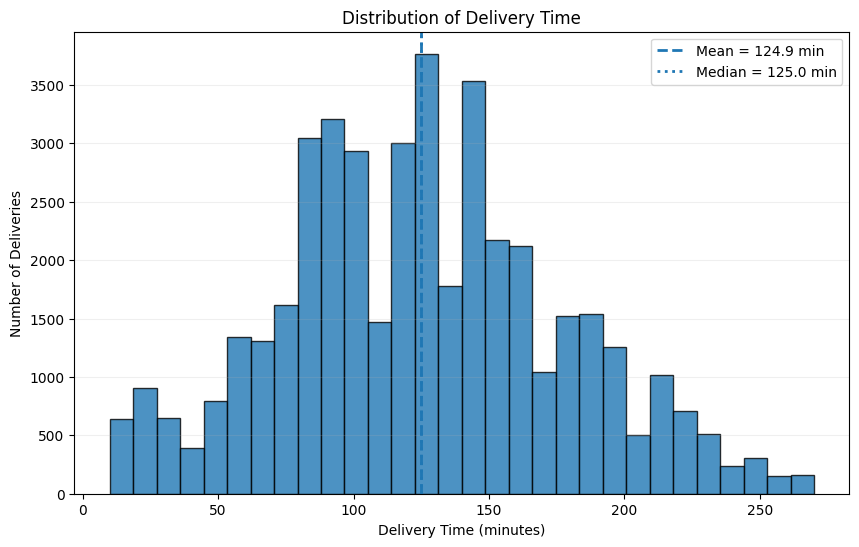

In [33]:
# ============================================================
# 7.2 DELIVERY TIME DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    df["Delivery_Time"],
    bins=30,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    df["Delivery_Time"].mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {df['Delivery_Time'].mean():.1f} min"
)

plt.axvline(
    df["Delivery_Time"].median(),
    linestyle=":",
    linewidth=2,
    label=f"Median = {df['Delivery_Time'].median():.1f} min"
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Deliveries")
plt.legend()
plt.grid(axis="y", alpha=0.2)

plt.show()

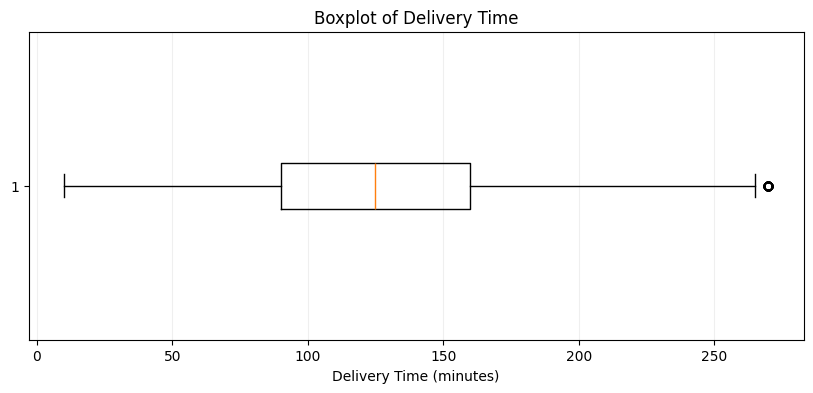

In [34]:
# ============================================================
# 7.2 DELIVERY TIME BOXPLOT
# ============================================================

plt.figure(figsize=(10, 4))

plt.boxplot(
    df["Delivery_Time"],
    vert=False
)

plt.title("Boxplot of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.grid(axis="x", alpha=0.2)

plt.show()

### 7.2 Delivery-Time Distribution Interpretation

The cleaned dataset contains delivery times ranging from **10 to 270 minutes**, with a mean of approximately **124.91 minutes** and a median of **125 minutes**.

The first quartile is **90 minutes** and the third quartile is **160 minutes**, meaning that approximately half of all deliveries fall between 90 and 160 minutes.

The mean and median are nearly identical, and the skewness value of **0.188** indicates only a slight positive skew. Therefore, the target variable is relatively balanced rather than being strongly skewed toward unusually long delivery durations.

The standard deviation is approximately **51.93 minutes**, indicating substantial variability in delivery duration across observations.

The boxplot identifies a small number of observations at the extreme upper end of the delivery-time distribution. These observations are not automatically removed because long delivery times may represent legitimate high-risk delivery situations associated with factors such as traffic, weather, distance, or operational conditions.

Retaining these observations is particularly important because identifying deliveries associated with unusually long durations is central to the objective of this study.

### 7.3 Traffic Conditions and Delivery Time

Traffic conditions are expected to have a direct relationship with delivery duration.

The dataset categorizes traffic conditions as:

- Low
- Medium
- High
- Jam

To investigate the relationship between traffic and delivery performance, average and median delivery times are compared across traffic categories.

If delivery time systematically increases as traffic conditions become more severe, traffic is likely to be an important predictive feature.

In [35]:
# ============================================================
# 7.3 TRAFFIC CONDITIONS VS DELIVERY TIME
# ============================================================

traffic_summary = (
    df.groupby("Traffic")["Delivery_Time"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std"
    )
    .round(2)
)

traffic_order = ["Low", "Medium", "High", "Jam"]

traffic_summary = traffic_summary.reindex(traffic_order)

display(traffic_summary)

,Count,Mean,Median,Std_Dev
Traffic,,,,
Low,14999,101.35,100.0,38.80
Medium,10628,126.84,130.0,48.71
High,4296,129.42,135.0,48.27
Jam,13725,147.76,150.0,56.81


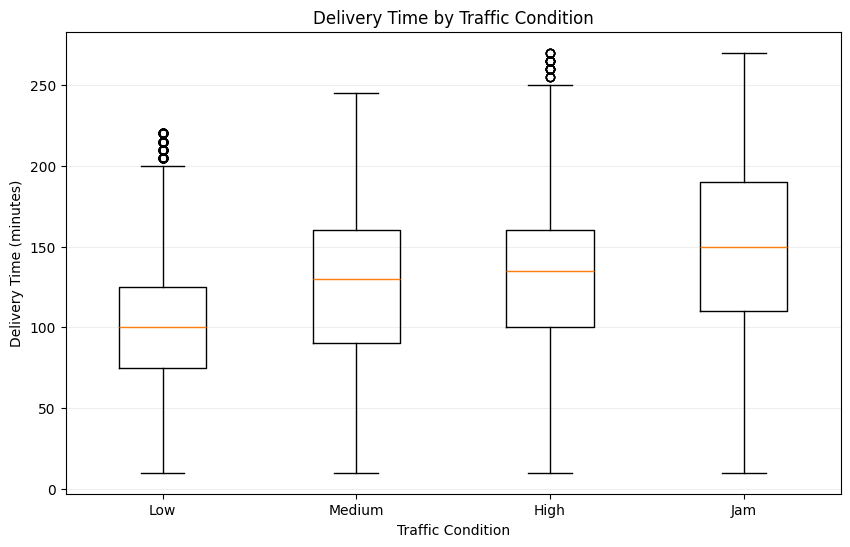

In [36]:
# ============================================================
# TRAFFIC CONDITIONS - BOXPLOT
# ============================================================

traffic_data = [
    df.loc[df["Traffic"] == category, "Delivery_Time"]
    for category in traffic_order
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    traffic_data,
    tick_labels=traffic_order
)

plt.title("Delivery Time by Traffic Condition")
plt.xlabel("Traffic Condition")
plt.ylabel("Delivery Time (minutes)")
plt.grid(axis="y", alpha=0.2)

plt.show()

### 7.4 Weather Conditions and Delivery Time

Weather may influence delivery duration by affecting road conditions, driving speed, visibility, and delivery-agent mobility.

Average and median delivery times are compared across weather conditions to determine whether certain environmental conditions are systematically associated with longer deliveries.

In [37]:
# ============================================================
# 7.4 WEATHER CONDITIONS VS DELIVERY TIME
# ============================================================

weather_summary = (
    df.groupby("Weather")["Delivery_Time"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std"
    )
    .sort_values("Mean")
    .round(2)
)

display(weather_summary)

,Count,Mean,Median,Std_Dev
Weather,,,,
Sunny,7078,103.66,100.0,45.44
Stormy,7374,123.21,125.0,47.80
Sandstorms,7245,123.24,125.0,48.31
Windy,7223,123.66,125.0,48.52
Fog,7440,136.57,135.0,57.23
Cloudy,7288,138.29,140.0,55.47


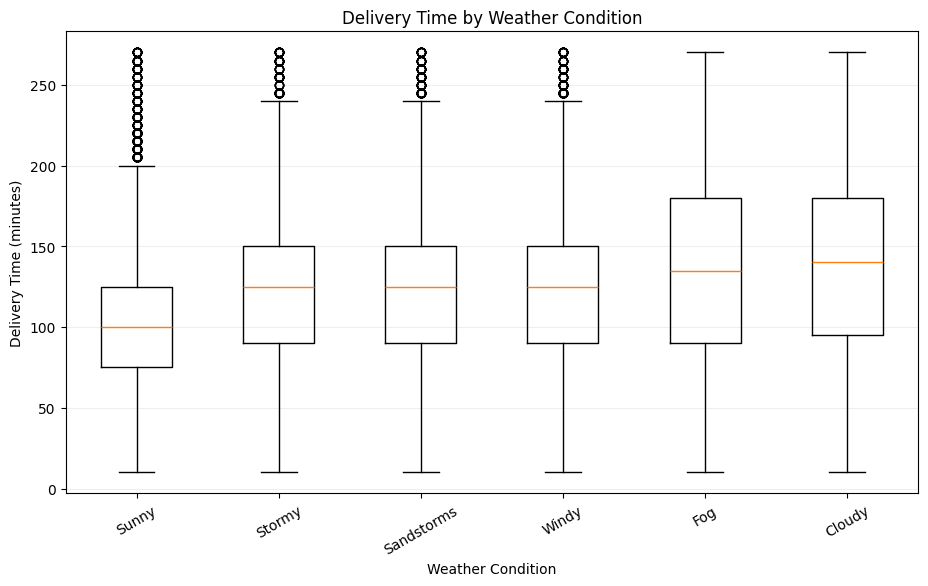

In [38]:
# ============================================================
# WEATHER CONDITIONS - BOXPLOT
# ============================================================

weather_order = weather_summary.index.tolist()

weather_data = [
    df.loc[df["Weather"] == category, "Delivery_Time"]
    for category in weather_order
]

plt.figure(figsize=(11, 6))

plt.boxplot(
    weather_data,
    tick_labels=weather_order
)

plt.title("Delivery Time by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Delivery Time (minutes)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.2)

plt.show()

### 7.5 Delivery Area and Delivery Time

Delivery area may reflect differences in road structure, population density, accessibility, congestion, and delivery complexity.

The dataset contains four area categories:

- Metropolitan
- Urban
- Semi-Urban
- Other

Delivery-time distributions are compared across these areas to determine whether location type is associated with meaningful differences in delivery duration.

In [39]:
# ============================================================
# 7.5 AREA VS DELIVERY TIME
# ============================================================

area_summary = (
    df.groupby("Area")["Delivery_Time"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std"
    )
    .sort_values("Mean")
    .round(2)
)

display(area_summary)

,Count,Mean,Median,Std_Dev
Area,,,,
Other,1136,104.50,100.0,45.98
Urban,9726,109.44,105.0,48.22
Metropolitan,32634,129.71,130.0,51.59
Semi-Urban,152,238.55,245.0,47.03


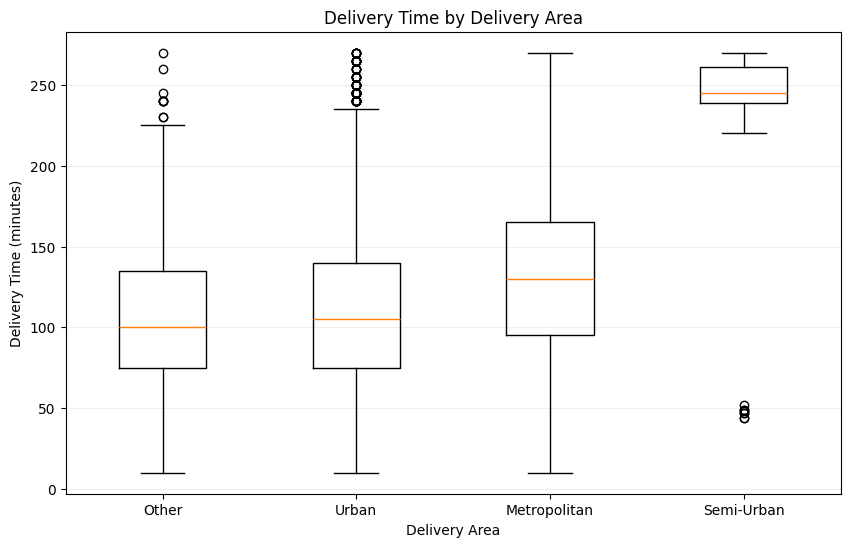

In [40]:
# ============================================================
# DELIVERY AREA - BOXPLOT
# ============================================================

area_order = area_summary.index.tolist()

area_data = [
    df.loc[df["Area"] == category, "Delivery_Time"]
    for category in area_order
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    area_data,
    tick_labels=area_order
)

plt.title("Delivery Time by Delivery Area")
plt.xlabel("Delivery Area")
plt.ylabel("Delivery Time (minutes)")
plt.grid(axis="y", alpha=0.2)

plt.show()

### 7.6 Vehicle Type and Delivery Time

Vehicle type may influence delivery speed, especially under different traffic, road, and geographic conditions.

The relationship between vehicle type and delivery time is examined to determine whether transportation mode contributes meaningful predictive information.

In [41]:
# ============================================================
# 7.6 VEHICLE TYPE VS DELIVERY TIME
# ============================================================

vehicle_summary = (
    df.groupby("Vehicle")["Delivery_Time"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std"
    )
    .sort_values("Mean")
    .round(2)
)

display(vehicle_summary)

,Count,Mean,Median,Std_Dev
Vehicle,,,,
van,3522,116.17,115.0,47.84
scooter,14607,116.35,115.0,48.19
motorcycle,25519,131.03,130.0,53.65


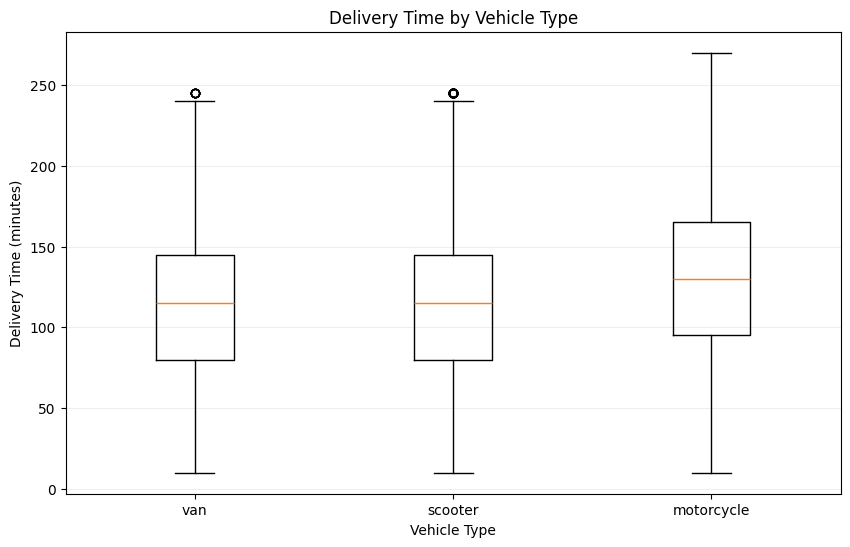

In [42]:
# ============================================================
# VEHICLE TYPE - BOXPLOT
# ============================================================

vehicle_order = vehicle_summary.index.tolist()

vehicle_data = [
    df.loc[df["Vehicle"] == category, "Delivery_Time"]
    for category in vehicle_order
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    vehicle_data,
    tick_labels=vehicle_order
)

plt.title("Delivery Time by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Delivery Time (minutes)")
plt.grid(axis="y", alpha=0.2)

plt.show()

### 7.7 Interpretation of Categorical Delivery Factors

The exploratory analysis indicates that several operational and environmental variables are associated with meaningful differences in delivery time.

#### Traffic Conditions

Traffic shows a clear relationship with delivery duration.

- Low traffic: mean = **101.35 minutes**, median = **100 minutes**
- Medium traffic: mean = **126.84 minutes**, median = **130 minutes**
- High traffic: mean = **129.42 minutes**, median = **135 minutes**
- Traffic jam: mean = **147.76 minutes**, median = **150 minutes**

Deliveries completed during traffic jams take approximately **46 minutes longer on average** than deliveries completed under low-traffic conditions.

This pattern suggests that traffic condition is likely to be an important predictor of delivery duration.

#### Weather Conditions

Delivery time also varies meaningfully across weather conditions.

- Sunny: mean = **103.66 minutes**
- Stormy: mean = **123.21 minutes**
- Sandstorms: mean = **123.24 minutes**
- Windy: mean = **123.66 minutes**
- Fog: mean = **136.57 minutes**
- Cloudy: mean = **138.29 minutes**

Sunny conditions are associated with the shortest average delivery times, while cloudy and foggy conditions are associated with the longest average delivery times.

This suggests that weather conditions may provide useful predictive information.

#### Delivery Area

Delivery area shows substantial differences in delivery duration.

- Other: mean = **104.50 minutes**
- Urban: mean = **109.44 minutes**
- Metropolitan: mean = **129.71 minutes**
- Semi-Urban: mean = **238.55 minutes**

Semi-Urban deliveries have substantially longer delivery times than all other areas.

However, the Semi-Urban category contains only **152 observations**, compared with **32,634 Metropolitan deliveries**. Therefore, this large difference should be interpreted cautiously because the Semi-Urban group represents a relatively small portion of the dataset.

#### Vehicle Type

Vehicle type is also associated with differences in delivery duration.

- Van: mean = **116.17 minutes**
- Scooter: mean = **116.35 minutes**
- Motorcycle: mean = **131.03 minutes**

Motorcycle deliveries have higher average delivery times than van and scooter deliveries.

However, these results should not be interpreted as evidence that motorcycle use itself causes longer deliveries. Vehicle assignment may be related to other characteristics such as delivery distance, traffic conditions, geographic area, or order type.

### Overall Interpretation

Traffic, weather, delivery area, and vehicle type all demonstrate observable associations with delivery time.

These results support retaining these variables as candidate predictors for later machine learning analysis. However, the relationships observed during EDA are **associational rather than causal**, and multiple variables may interact with one another.

The machine learning stage will evaluate these factors jointly rather than drawing conclusions from any single variable in isolation.

### 7.8 Product Category and Delivery Time

Product category may affect delivery duration because different products may involve different handling requirements, preparation times, packaging processes, or delivery priorities.

The dataset contains multiple product categories. Average and median delivery times are compared to determine whether category contributes useful predictive information.

In [43]:
# ============================================================
# 7.8 PRODUCT CATEGORY VS DELIVERY TIME
# ============================================================

category_summary = (
    df.groupby("Category")["Delivery_Time"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std"
    )
    .sort_values("Mean")
    .round(2)
)

display(category_summary)

,Count,Mean,Median,Std_Dev
Category,,,,
Grocery,2688,26.54,26.0,9.50
Toys,2773,129.37,125.0,47.19
Clothing,2662,130.49,125.0,47.31
Jewelry,2796,130.75,125.0,46.99
Electronics,2843,130.87,125.0,45.29
Home,2680,130.96,125.0,47.50
Books,2817,131.05,125.0,46.95
Shoes,2661,131.11,130.0,46.29
Outdoors,2741,131.15,125.0,46.70


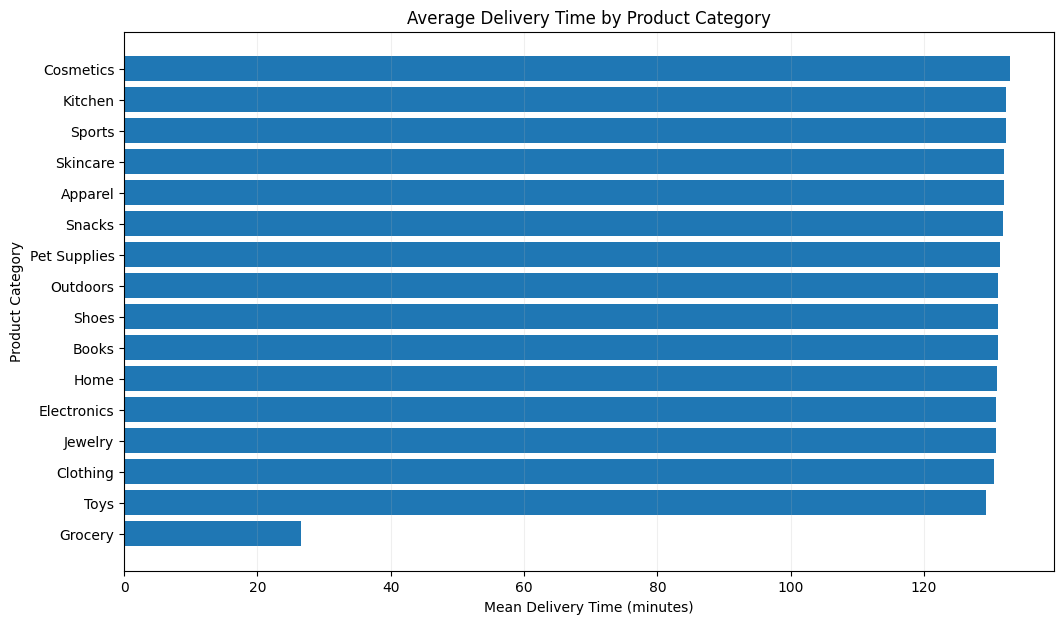

In [44]:
# ============================================================
# PRODUCT CATEGORY - MEAN DELIVERY TIME
# ============================================================

plt.figure(figsize=(12, 7))

plt.barh(
    category_summary.index,
    category_summary["Mean"]
)

plt.title("Average Delivery Time by Product Category")
plt.xlabel("Mean Delivery Time (minutes)")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.2)

plt.show()

### 7.9 Delivery Agent Age and Delivery Time

Delivery-agent characteristics may influence delivery performance through factors such as experience, familiarity with delivery processes, or physical demands associated with the work.

Agent age is first examined by comparing average delivery time across age values.

This analysis is exploratory and does not imply that age itself causes differences in delivery performance.

In [45]:
# ============================================================
# 7.9 AGENT AGE VS DELIVERY TIME
# ============================================================

age_summary = (
    df.groupby("Agent_Age")["Delivery_Time"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .round(2)
)

age_delivery_correlation = (
    df["Agent_Age"]
    .corr(df["Delivery_Time"])
)

print(
    f"Pearson correlation between Agent Age and Delivery Time: "
    f"{age_delivery_correlation:.3f}"
)

display(age_summary)

Pearson correlation between Agent Age and Delivery Time: 0.259


,Count,Mean,Median
Agent_Age,,,
20,2136,108.77,105.0
21,2153,109.41,105.0
22,2196,108.72,105.0
23,2087,110.83,105.0
24,2210,108.99,105.0
25,2174,108.46,105.0
26,2159,109.38,105.0
27,2150,108.62,105.0
28,2179,110.82,105.0


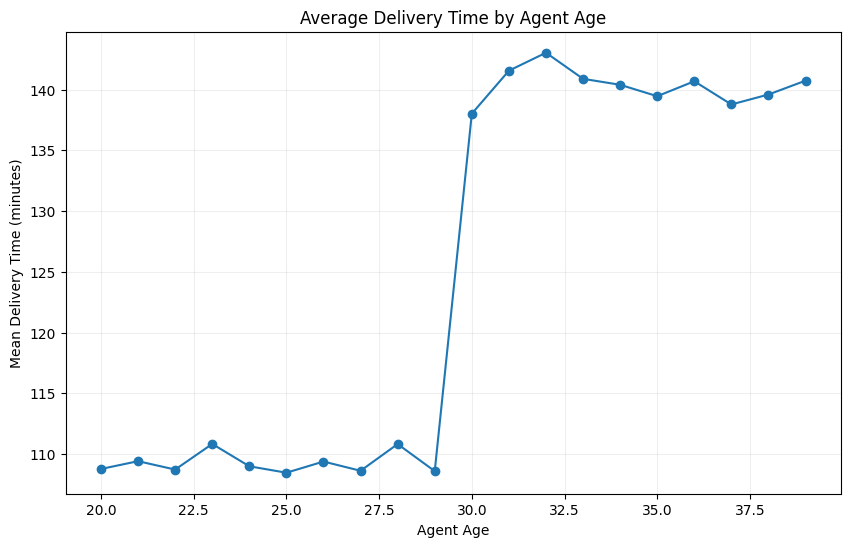

In [46]:
# ============================================================
# AGENT AGE - MEAN DELIVERY TIME
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    age_summary.index,
    age_summary["Mean"],
    marker="o"
)

plt.title("Average Delivery Time by Agent Age")
plt.xlabel("Agent Age")
plt.ylabel("Mean Delivery Time (minutes)")
plt.grid(alpha=0.2)

plt.show()

### 7.10 Agent Rating and Delivery Time

Agent rating may provide information about delivery performance or service quality.

The relationship between agent rating and delivery time is examined using both grouped averages and Pearson correlation.

Missing rating values are retained during this stage and automatically excluded from calculations requiring a valid rating. They will later be handled formally within the machine learning preprocessing pipeline.

In [47]:
# ============================================================
# 7.10 AGENT RATING VS DELIVERY TIME
# ============================================================

rating_summary = (
    df.dropna(subset=["Agent_Rating"])
    .groupby("Agent_Rating")["Delivery_Time"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .round(2)
)

rating_delivery_correlation = (
    df[["Agent_Rating", "Delivery_Time"]]
    .dropna()
    .corr()
    .iloc[0, 1]
)

print(
    f"Pearson correlation between Agent Rating and Delivery Time: "
    f"{rating_delivery_correlation:.3f}"
)

display(rating_summary)

Pearson correlation between Agent Rating and Delivery Time: -0.308


,Count,Mean,Median
Agent_Rating,,,
2.5,20,180.30,177.5
2.6,22,172.77,192.5
2.7,22,179.32,182.5
2.8,19,168.84,175.0
2.9,19,175.58,190.0
3.0,6,163.33,162.5
3.1,29,182.76,175.0
3.2,29,177.17,180.0
3.3,25,180.20,180.0


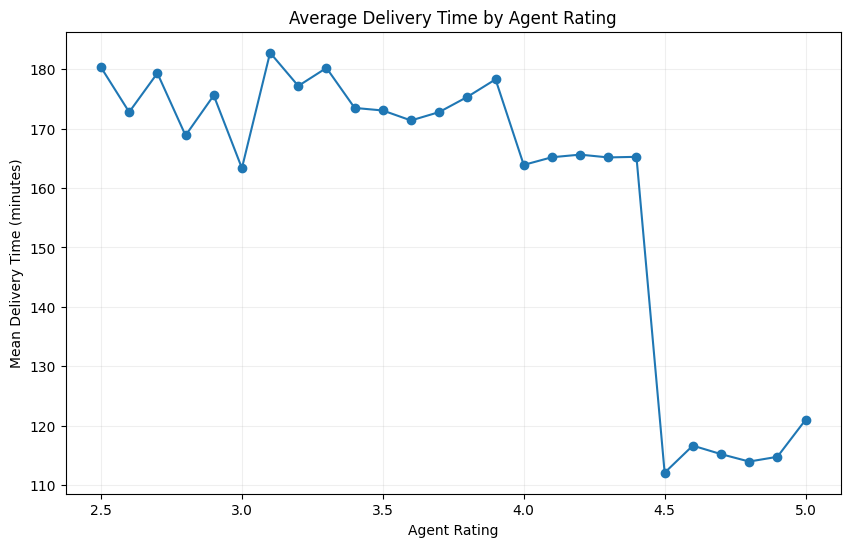

In [48]:
# ============================================================
# AGENT RATING - MEAN DELIVERY TIME
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    rating_summary.index,
    rating_summary["Mean"],
    marker="o"
)

plt.title("Average Delivery Time by Agent Rating")
plt.xlabel("Agent Rating")
plt.ylabel("Mean Delivery Time (minutes)")
plt.grid(alpha=0.2)

plt.show()

### 7.11 Order Time and Delivery Time

Delivery performance may vary throughout the day because traffic intensity, order demand, staffing levels, and operational conditions change over time.

The hour in which an order was placed is temporarily extracted from `Order_Time` for exploratory analysis.

The formal `Order_Hour` feature will be created later during the feature-engineering stage.

In [49]:
# ============================================================
# 7.11 ORDER HOUR VS DELIVERY TIME
# ============================================================

eda_order_hour = df["Order_Time"].dt.hour

order_hour_summary = (
    pd.DataFrame({
        "Order_Hour": eda_order_hour,
        "Delivery_Time": df["Delivery_Time"]
    })
    .groupby("Order_Hour")["Delivery_Time"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .round(2)
)

display(order_hour_summary)

,Count,Mean,Median
Order_Hour,,,
0,429,103.64,105.0
8,1810,93.04,90.0
9,1934,92.52,90.0
10,1980,93.02,90.0
11,1950,125.41,130.0
12,888,128.49,132.5
13,779,131.40,135.0
14,785,130.36,135.0
15,871,109.94,115.0


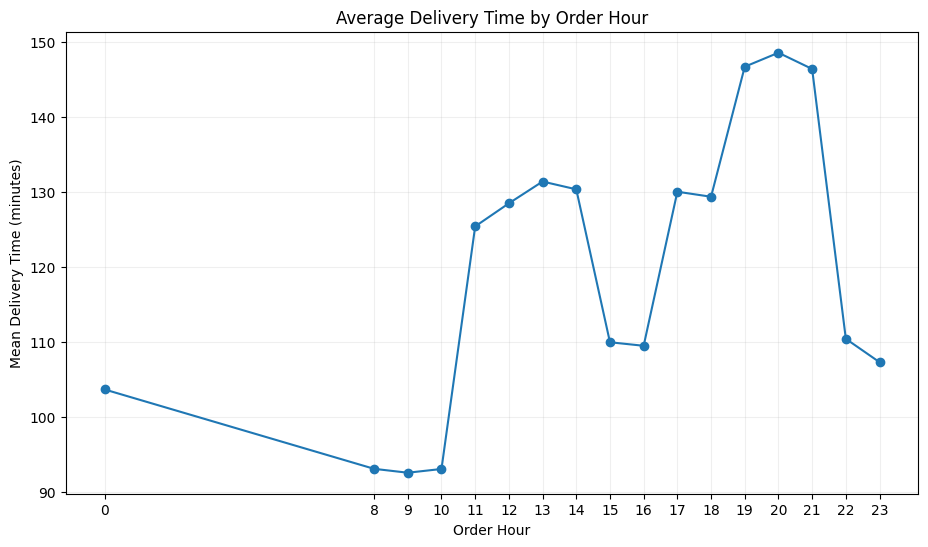

In [50]:
# ============================================================
# ORDER HOUR - MEAN DELIVERY TIME
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(
    order_hour_summary.index,
    order_hour_summary["Mean"],
    marker="o"
)

plt.title("Average Delivery Time by Order Hour")
plt.xlabel("Order Hour")
plt.ylabel("Mean Delivery Time (minutes)")
plt.xticks(order_hour_summary.index)
plt.grid(alpha=0.2)

plt.show()

## 8. Feature Engineering

Feature engineering transforms raw variables into representations that more directly describe the delivery process and may improve predictive performance.

Based on the exploratory analysis and the available variables, the following features will be created:

1. **Delivery Distance (km)** — geographic distance between the store and drop-off location.
2. **Pickup Wait Time (minutes)** — time between order placement and pickup.
3. **Order Hour** — hour of the day when the order was placed.
4. **Order Day of Week** — weekday associated with the order date.
5. **Weekend Indicator** — identifies whether the order occurred on Saturday or Sunday.

A separate modeling dataset is created so that the cleaned dataset remains unchanged.

In [51]:
# ============================================================
# SECTION 8: FEATURE ENGINEERING
# 8.1 CREATE MODELING DATASET
# ============================================================

# Preserve the cleaned dataset and create a separate copy
# for feature engineering and machine-learning preparation.
df_model = df.copy()

print("Modeling dataset created successfully!")
print("=" * 60)
print(f"Rows    : {df_model.shape[0]:,}")
print(f"Columns : {df_model.shape[1]}")

Modeling dataset created successfully!
Rows    : 43,648
Columns : 16


### 8.2 Delivery Distance

The dataset provides separate latitude and longitude coordinates for the store and drop-off location. However, raw coordinates do not directly represent the distance traveled between the two locations.

A new feature, `Delivery_Distance_km`, is therefore calculated using the **Haversine formula**, which estimates the great-circle distance between two geographic coordinates on the Earth's surface.

This converts four raw coordinate variables into a single interpretable measure of approximate delivery distance.

The previously identified zero-coordinate records are retained. Their distance values are interpreted cautiously because their absolute store locations are uncertain, although their relative coordinate displacement was found to be consistent with the remainder of the dataset.

In [52]:
# ============================================================
# 8.2 DELIVERY DISTANCE
# ============================================================

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate great-circle distance between two geographic
    coordinates using the Haversine formula.

    Returns
    -------
    Distance in kilometers.
    """

    earth_radius_km = 6371.0

    # Convert degrees to radians
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    # Coordinate differences
    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    # Haversine formula
    a = (
        np.sin(delta_lat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(delta_lon / 2) ** 2
    )

    # Protect against tiny floating-point errors
    a = np.clip(a, 0, 1)

    c = 2 * np.arctan2(
        np.sqrt(a),
        np.sqrt(1 - a)
    )

    return earth_radius_km * c


df_model["Delivery_Distance_km"] = haversine_distance(
    df_model["Store_Latitude"],
    df_model["Store_Longitude"],
    df_model["Drop_Latitude"],
    df_model["Drop_Longitude"]
)

print("DELIVERY DISTANCE FEATURE")
print("=" * 60)

display(
    df_model["Delivery_Distance_km"]
    .describe()
    .round(2)
    .rename("Distance_km")
    .to_frame()
)

DELIVERY DISTANCE FEATURE


,Distance_km
count,43648.00
mean,9.73
std,5.60
min,1.47
25%,4.66
50%,9.22
75%,13.68
max,20.97


In [53]:
# Validate the engineered distance feature

distance_validation = pd.DataFrame({
    "Metric": [
        "Missing distances",
        "Distances <= 0",
        "Minimum distance (km)",
        "Maximum distance (km)",
        "Average distance (km)"
    ],
    "Value": [
        df_model["Delivery_Distance_km"].isna().sum(),
        (df_model["Delivery_Distance_km"] <= 0).sum(),
        df_model["Delivery_Distance_km"].min(),
        df_model["Delivery_Distance_km"].max(),
        df_model["Delivery_Distance_km"].mean()
    ]
})

display(distance_validation.round(2))

,Metric,Value
0,Missing distances,0.00
1,Distances <= 0,0.00
2,Minimum distance (km),1.47
3,Maximum distance (km),20.97
4,Average distance (km),9.73


### 8.3 Pickup Wait Time

`Order_Time` and `Pickup_Time` can be combined to estimate how long an order waited before pickup.

A direct subtraction can produce incorrect negative values when an order is placed before midnight and picked up after midnight. For example, an order placed at 11:50 PM and picked up at 12:10 AM should have a 20-minute wait, not a large negative value.

To handle this correctly, pickup times that appear earlier than their corresponding order times are treated as occurring on the following day.

The resulting feature, `Pickup_Wait_Minutes`, represents the elapsed time between order placement and pickup.

In [54]:
# ============================================================
# 8.3 PICKUP WAIT TIME
# ============================================================

# Convert time-of-day values into total minutes after midnight
order_minutes = (
    df_model["Order_Time"].dt.hour * 60
    + df_model["Order_Time"].dt.minute
)

pickup_minutes = (
    df_model["Pickup_Time"].dt.hour * 60
    + df_model["Pickup_Time"].dt.minute
)

# Initial difference
pickup_wait = pickup_minutes - order_minutes

# If pickup appears earlier than order time,
# treat pickup as occurring after midnight on the next day.
midnight_rollover = pickup_wait < 0

pickup_wait.loc[midnight_rollover] += 24 * 60

df_model["Pickup_Wait_Minutes"] = pickup_wait

print("PICKUP WAIT TIME FEATURE")
print("=" * 60)
print(f"Midnight rollover records : {midnight_rollover.sum():,}")

display(
    df_model["Pickup_Wait_Minutes"]
    .describe()
    .round(2)
    .rename("Pickup_Wait_Minutes")
    .to_frame()
)

PICKUP WAIT TIME FEATURE
Midnight rollover records : 828


,Pickup_Wait_Minutes
count,43648.00
mean,9.99
std,4.09
min,5.00
25%,5.00
50%,10.00
75%,15.00
max,15.00


In [55]:
# Validate pickup waiting time

pickup_wait_validation = pd.DataFrame({
    "Metric": [
        "Missing wait times",
        "Negative wait times",
        "Zero wait times",
        "Minimum wait (minutes)",
        "Maximum wait (minutes)",
        "Average wait (minutes)",
        "Midnight rollover records"
    ],
    "Value": [
        df_model["Pickup_Wait_Minutes"].isna().sum(),
        (df_model["Pickup_Wait_Minutes"] < 0).sum(),
        (df_model["Pickup_Wait_Minutes"] == 0).sum(),
        df_model["Pickup_Wait_Minutes"].min(),
        df_model["Pickup_Wait_Minutes"].max(),
        df_model["Pickup_Wait_Minutes"].mean(),
        midnight_rollover.sum()
    ]
})

display(pickup_wait_validation.round(2))

,Metric,Value
0,Missing wait times,0.00
1,Negative wait times,0.00
2,Zero wait times,0.00
3,Minimum wait (minutes),5.00
4,Maximum wait (minutes),15.00
5,Average wait (minutes),9.99
6,Midnight rollover records,828.00


#### Interpretation

A total of 828 records required midnight rollover correction.

Without this correction, these observations would produce large negative pickup waiting times and introduce unrealistic values into the modeling dataset.

After adjustment, all pickup waiting times are non-negative, making the feature suitable for later model development.

### 8.4 Temporal Features

The delivery process may vary depending on when an order is placed. To represent these time-based patterns more clearly, three temporal features are created:

1. **Order_Hour** — the hour of day when the order was placed.
2. **Order_DayOfWeek** — the weekday corresponding to the order date.
3. **Is_Weekend** — a binary indicator showing whether the order occurred on Saturday or Sunday.

These variables allow the models to capture recurring time-of-day and weekly delivery patterns more directly than the raw date and time values.

In [56]:
# ============================================================
# 8.4 TEMPORAL FEATURES
# ============================================================

# Hour of day
df_model["Order_Hour"] = df_model["Order_Time"].dt.hour

# Day of week
df_model["Order_DayOfWeek"] = df_model["Order_Date"].dt.day_name()

# Weekend indicator
df_model["Is_Weekend"] = (
    df_model["Order_Date"].dt.dayofweek >= 5
).astype(int)

print("TEMPORAL FEATURES CREATED")
print("=" * 60)

display(
    df_model[
        [
            "Order_Date",
            "Order_Time",
            "Order_Hour",
            "Order_DayOfWeek",
            "Is_Weekend"
        ]
    ].head(10)
)

TEMPORAL FEATURES CREATED


,Order_Date,Order_Time,Order_Hour,Order_DayOfWeek,Is_Weekend
0,2022-03-19,1900-01-01 11:30:00,11,Saturday,1
1,2022-03-25,1900-01-01 19:45:00,19,Friday,0
2,2022-03-19,1900-01-01 08:30:00,8,Saturday,1
3,2022-04-05,1900-01-01 18:00:00,18,Tuesday,0
4,2022-03-26,1900-01-01 13:30:00,13,Saturday,1
5,2022-03-11,1900-01-01 21:20:00,21,Friday,0
6,2022-03-04,1900-01-01 19:15:00,19,Friday,0
7,2022-03-14,1900-01-01 17:25:00,17,Monday,0
8,2022-03-20,1900-01-01 20:55:00,20,Sunday,1
9,2022-02-12,1900-01-01 21:55:00,21,Saturday,1


In [57]:
# Validate temporal features

temporal_validation = pd.DataFrame({
    "Metric": [
        "Missing Order_Hour",
        "Minimum Order_Hour",
        "Maximum Order_Hour",
        "Missing Order_DayOfWeek",
        "Missing Is_Weekend",
        "Weekend records"
    ],
    "Value": [
        df_model["Order_Hour"].isna().sum(),
        df_model["Order_Hour"].min(),
        df_model["Order_Hour"].max(),
        df_model["Order_DayOfWeek"].isna().sum(),
        df_model["Is_Weekend"].isna().sum(),
        df_model["Is_Weekend"].sum()
    ]
})

display(temporal_validation)

,Metric,Value
0,Missing Order_Hour,0
1,Minimum Order_Hour,0
2,Maximum Order_Hour,23
3,Missing Order_DayOfWeek,0
4,Missing Is_Weekend,0
5,Weekend records,12021


In [58]:
print("ORDERS BY DAY OF WEEK")
print("=" * 60)

display(
    df_model["Order_DayOfWeek"]
    .value_counts()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
    .rename("Order_Count")
    .to_frame()
)

print("\nWEEKEND DISTRIBUTION")
print("=" * 60)

display(
    df_model["Is_Weekend"]
    .value_counts()
    .rename(index={
        0: "Weekday",
        1: "Weekend"
    })
    .rename("Order_Count")
    .to_frame()
)

ORDERS BY DAY OF WEEK


,Order_Count
Order_DayOfWeek,
Monday,5944
Tuesday,6072
Wednesday,6783
Thursday,6087
Friday,6741
Saturday,6033
Sunday,5988



WEEKEND DISTRIBUTION


,Order_Count
Is_Weekend,
Weekday,31627
Weekend,12021


#### Interpretation

The engineered temporal variables provide model-friendly representations of the original order date and time information.

`Order_Hour` captures time-of-day effects observed during exploratory analysis, while `Order_DayOfWeek` and `Is_Weekend` allow the models to learn recurring weekly patterns.

These features will later be included in the preprocessing and model-training pipeline.

### 8.5 Feature Engineering Summary

The feature-engineering stage transformed raw geographic and temporal variables into more interpretable predictors that better represent the delivery process.

The newly created features are:

- `Delivery_Distance_km` — approximate geographic distance between the store and drop-off location.
- `Pickup_Wait_Minutes` — elapsed time between order placement and pickup, including midnight rollover correction.
- `Order_Hour` — hour of day when the order was placed.
- `Order_DayOfWeek` — weekday associated with the order date.
- `Is_Weekend` — binary indicator identifying Saturday and Sunday orders.

Before moving into machine-learning preprocessing, these engineered features are validated for missing values, invalid ranges, and consistency.

In [59]:
# ============================================================
# 8.5 FEATURE ENGINEERING VALIDATION
# ============================================================

engineered_features = [
    "Delivery_Distance_km",
    "Pickup_Wait_Minutes",
    "Order_Hour",
    "Order_DayOfWeek",
    "Is_Weekend"
]

feature_validation = pd.DataFrame({
    "Feature": engineered_features,
    "Missing_Values": [
        df_model[col].isna().sum()
        for col in engineered_features
    ],
    "Unique_Values": [
        df_model[col].nunique(dropna=True)
        for col in engineered_features
    ]
})

display(feature_validation)

,Feature,Missing_Values,Unique_Values
0,Delivery_Distance_km,0,4366
1,Pickup_Wait_Minutes,0,3
2,Order_Hour,0,17
3,Order_DayOfWeek,0,7
4,Is_Weekend,0,2


In [60]:
# Numerical engineered feature summary

numerical_engineered_features = [
    "Delivery_Distance_km",
    "Pickup_Wait_Minutes",
    "Order_Hour",
    "Is_Weekend"
]

display(
    df_model[numerical_engineered_features]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
Delivery_Distance_km,43648.0,9.73,5.60,1.47,4.66,9.22,13.68,20.97
Pickup_Wait_Minutes,43648.0,9.99,4.09,5.00,5.00,10.00,15.00,15.00
Order_Hour,43648.0,17.43,4.82,0.00,15.00,19.00,21.00,23.00
Is_Weekend,43648.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00


In [61]:
# Final feature-engineering quality checks

feature_quality_checks = pd.DataFrame({
    "Check": [
        "Negative delivery distances",
        "Zero/negative delivery distances",
        "Negative pickup wait times",
        "Order hour below 0",
        "Order hour above 23",
        "Invalid weekend indicators"
    ],
    "Count": [
        (df_model["Delivery_Distance_km"] < 0).sum(),
        (df_model["Delivery_Distance_km"] <= 0).sum(),
        (df_model["Pickup_Wait_Minutes"] < 0).sum(),
        (df_model["Order_Hour"] < 0).sum(),
        (df_model["Order_Hour"] > 23).sum(),
        (~df_model["Is_Weekend"].isin([0, 1])).sum()
    ]
})

display(feature_quality_checks)

,Check,Count
0,Negative delivery distances,0
1,Zero/negative delivery distances,0
2,Negative pickup wait times,0
3,Order hour below 0,0
4,Order hour above 23,0
5,Invalid weekend indicators,0


#### Feature Engineering Validation

The engineered features passed the required quality checks.

Delivery distance values were positive, pickup waiting times contained no negative values after midnight rollover correction, order-hour values remained within the valid 0–23 range, and the weekend indicator contained only valid binary values.

The modeling dataset is therefore ready for preprocessing and train-test preparation.

In [62]:
print("FINAL MODELING DATASET")
print("=" * 60)
print(f"Rows    : {df_model.shape[0]:,}")
print(f"Columns : {df_model.shape[1]}")

print("\nNew engineered features:")
for feature in engineered_features:
    print(f"✓ {feature}")

FINAL MODELING DATASET
Rows    : 43,648
Columns : 21

New engineered features:
✓ Delivery_Distance_km
✓ Pickup_Wait_Minutes
✓ Order_Hour
✓ Order_DayOfWeek
✓ Is_Weekend


## 9. Modeling Dataset and Preprocessing

The next stage prepares the engineered dataset for machine-learning model development.

The target variable is:

- `Delivery_Time` — observed delivery duration in minutes.

Predictor variables are selected based on the exploratory analysis, feature-engineering results, and their relevance to the delivery process.

Raw identifiers, original date/time fields, and raw geographic coordinates are excluded from direct modeling because:

- `Order_ID` is an identifier and does not describe delivery behavior.
- `Order_Date`, `Order_Time`, and `Pickup_Time` have been converted into more useful engineered temporal features.
- Raw latitude and longitude values are replaced by the more interpretable `Delivery_Distance_km` feature.
- `Delivery_Time` is the target variable and must never be included among the predictors.

The selected predictors are divided into numerical and categorical features so that appropriate preprocessing can later be applied to each group.

In [63]:
# ============================================================
# SECTION 9: MODELING DATASET AND PREPROCESSING
# 9.1 FEATURE SELECTION
# ============================================================

target = "Delivery_Time"

numerical_features = [
    "Agent_Age",
    "Agent_Rating",
    "Delivery_Distance_km",
    "Pickup_Wait_Minutes",
    "Order_Hour",
    "Is_Weekend"
]

categorical_features = [
    "Weather",
    "Traffic",
    "Vehicle",
    "Area",
    "Category",
    "Order_DayOfWeek"
]

model_features = numerical_features + categorical_features

# Predictor matrix
X = df_model[model_features].copy()

# Target
y = df_model[target].copy()

print("MODEL FEATURE SELECTION")
print("=" * 60)

print(f"Number of observations : {len(X):,}")
print(f"Number of predictors   : {len(model_features)}")
print(f"Numerical predictors   : {len(numerical_features)}")
print(f"Categorical predictors : {len(categorical_features)}")
print(f"Target variable         : {target}")

MODEL FEATURE SELECTION
Number of observations : 43,648
Number of predictors   : 12
Numerical predictors   : 6
Categorical predictors : 6
Target variable         : Delivery_Time


In [64]:
feature_summary = pd.DataFrame({
    "Feature": model_features,
    "Type": (
        ["Numerical"] * len(numerical_features)
        + ["Categorical"] * len(categorical_features)
    )
})

display(feature_summary)

,Feature,Type
0,Agent_Age,Numerical
1,Agent_Rating,Numerical
2,Delivery_Distance_km,Numerical
3,Pickup_Wait_Minutes,Numerical
4,Order_Hour,Numerical
5,Is_Weekend,Numerical
6,Weather,Categorical
7,Traffic,Categorical
8,Vehicle,Categorical
9,Area,Categorical


In [65]:
print("MISSING VALUES IN MODELING FEATURES")
print("=" * 60)

missing_model_features = (
    X.isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_model_features
    .rename("Missing_Values")
    .to_frame()
)

MISSING VALUES IN MODELING FEATURES


,Missing_Values
Agent_Rating,54
Agent_Age,0
Delivery_Distance_km,0
Pickup_Wait_Minutes,0
Order_Hour,0
Is_Weekend,0
Weather,0
Traffic,0
Vehicle,0
Area,0


#### Feature Selection Interpretation

A total of 12 predictors were selected for model development: six numerical features and six categorical features.

The remaining 54 missing `Agent_Rating` values are intentionally preserved at this stage. They will be handled using median imputation within the preprocessing pipeline after the train-test split.

This approach prevents information from the test dataset from influencing preprocessing decisions and reduces the risk of data leakage.

### 9.2 Train-Test Split

The dataset is divided into separate training and testing subsets before preprocessing.

- **80% training data** is used to fit the preprocessing steps and machine-learning models.
- **20% testing data** is reserved for final evaluation.

The test set remains unseen during training so that model performance can be evaluated on new data.

A fixed `random_state = 42` is used to make the split reproducible.

In [66]:
# ============================================================
# 9.2 TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("TRAIN-TEST SPLIT")
print("=" * 60)

print(f"Full dataset     : {len(X):,}")
print(f"Training records : {len(X_train):,}")
print(f"Testing records  : {len(X_test):,}")

print(f"\nTraining % : {len(X_train) / len(X) * 100:.2f}%")
print(f"Testing %  : {len(X_test) / len(X) * 100:.2f}%")

TRAIN-TEST SPLIT
Full dataset     : 43,648
Training records : 34,918
Testing records  : 8,730

Training % : 80.00%
Testing %  : 20.00%


In [67]:
# Compare target distributions across the split

target_split_summary = pd.DataFrame({
    "Dataset": ["Full", "Training", "Testing"],
    "Count": [
        len(y),
        len(y_train),
        len(y_test)
    ],
    "Mean_Delivery_Time": [
        y.mean(),
        y_train.mean(),
        y_test.mean()
    ],
    "Median_Delivery_Time": [
        y.median(),
        y_train.median(),
        y_test.median()
    ],
    "Std_Dev": [
        y.std(),
        y_train.std(),
        y_test.std()
    ]
})

display(target_split_summary.round(2))

,Dataset,Count,Mean_Delivery_Time,Median_Delivery_Time,Std_Dev
0,Full,43648,124.91,125.0,51.93
1,Training,34918,124.70,125.0,51.89
2,Testing,8730,125.77,125.0,52.11


In [68]:
print("MISSING AGENT RATINGS AFTER SPLIT")
print("=" * 60)

print(
    f"Training set : "
    f"{X_train['Agent_Rating'].isna().sum()}"
)

print(
    f"Testing set  : "
    f"{X_test['Agent_Rating'].isna().sum()}"
)

MISSING AGENT RATINGS AFTER SPLIT
Training set : 42
Testing set  : 12


#### Train-Test Split Interpretation

The modeling dataset was divided into 80% training data and 20% testing data.

The training and testing subsets retained similar delivery-time distributions, indicating that the random split produced reasonably representative samples.

No missing-value imputation, categorical encoding, or scaling was performed before the split. This ensures that preprocessing parameters are learned only from the training data and prevents information from the test set from leaking into model development.

### 9.3 Preprocessing Pipeline

Different predictor types require different preprocessing steps before they can be used by machine-learning models.

For numerical variables:

- Missing `Agent_Rating` values are imputed using the median calculated from the training data.
- Numerical features are standardized using `StandardScaler` so that variables with different measurement scales are placed on a comparable scale.

For categorical variables:

- Missing categorical values, if any, are handled using the most frequent category.
- Categories are transformed using one-hot encoding.
- Unknown categories that may appear in the test set are ignored rather than causing an error.

These preprocessing steps are combined using a `ColumnTransformer`. The transformer will later be placed inside each model pipeline so that preprocessing is learned only from the training data.

In [69]:
# ============================================================
# 9.3 PREPROCESSING PIPELINE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [70]:
# Fit preprocessing on TRAINING data only

X_train_processed = preprocessor.fit_transform(X_train)

# Transform the unseen TEST data using the already-fitted transformer
X_test_processed = preprocessor.transform(X_test)

print("PREPROCESSING RESULTS")
print("=" * 60)

print(
    f"Original training shape : {X_train.shape}"
)

print(
    f"Processed training shape: {X_train_processed.shape}"
)

print(
    f"Original testing shape  : {X_test.shape}"
)

print(
    f"Processed testing shape : {X_test_processed.shape}"
)

PREPROCESSING RESULTS
Original training shape : (34918, 12)
Processed training shape: (34918, 46)
Original testing shape  : (8730, 12)
Processed testing shape : (8730, 46)


In [71]:
# Check processed datasets for missing values

print("PROCESSED DATA VALIDATION")
print("=" * 60)

print(
    "Missing values in processed training data:",
    np.isnan(X_train_processed).sum()
)

print(
    "Missing values in processed testing data:",
    np.isnan(X_test_processed).sum()
)

PROCESSED DATA VALIDATION
Missing values in processed training data: 0
Missing values in processed testing data: 0


In [72]:
# Retrieve final feature names after preprocessing

processed_feature_names = (
    preprocessor
    .get_feature_names_out()
)

print(
    f"Total processed features: "
    f"{len(processed_feature_names)}"
)

display(
    pd.DataFrame({
        "Processed_Feature":
        processed_feature_names
    })
)

Total processed features: 46


,Processed_Feature
0,num__Agent_Age
1,num__Agent_Rating
2,num__Delivery_Distance_km
3,num__Pickup_Wait_Minutes
4,num__Order_Hour
5,num__Is_Weekend
6,cat__Weather_Cloudy
7,cat__Weather_Fog
8,cat__Weather_Sandstorms
9,cat__Weather_Stormy


#### Preprocessing Validation

The preprocessing pipeline successfully transformed the training and testing datasets without producing missing values.

Median imputation was used for numerical missing values, including the remaining missing `Agent_Rating` observations. Categorical predictors were one-hot encoded, while numerical features were standardized.

Importantly, the preprocessing transformer was fitted only on the training dataset. The same fitted transformations were then applied to the unseen test dataset.

This approach prevents test-set information from influencing preprocessing and helps maintain a valid evaluation procedure.

## 10. Baseline Model

Before evaluating more sophisticated machine-learning algorithms, a simple baseline model is established.

The baseline uses `DummyRegressor` with the mean strategy. This model does not learn relationships between the predictor variables and delivery time. Instead, it predicts the average delivery time observed in the training dataset for every test observation.

The baseline provides a minimum performance benchmark. More advanced models should outperform this benchmark to demonstrate that they are learning meaningful relationships from the predictors.

Performance is evaluated using:

- **Mean Absolute Error (MAE):** average absolute prediction error in minutes.
- **Root Mean Squared Error (RMSE):** gives greater penalty to large prediction errors.
- **R²:** proportion of variation in delivery time explained by the model.

In [73]:
# ============================================================
# SECTION 10: BASELINE MODEL
# ============================================================

from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.base import clone


# Build baseline pipeline
baseline_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            DummyRegressor(strategy="mean")
        )
    ]
)


# Train baseline using training data only
baseline_pipeline.fit(
    X_train,
    y_train
)


# Predict unseen test data
baseline_predictions = baseline_pipeline.predict(
    X_test
)


print("Baseline model trained successfully!")

Baseline model trained successfully!


In [74]:
# ============================================================
# 10.1 BASELINE MODEL EVALUATION
# ============================================================

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)


baseline_results = pd.DataFrame({
    "Model": ["Dummy Baseline"],
    "MAE": [baseline_mae],
    "RMSE": [baseline_rmse],
    "R2": [baseline_r2]
})


display(
    baseline_results.round(3)
)

,Model,MAE,RMSE,R2
0,Dummy Baseline,41.704,52.121,-0.0


In [75]:
print("BASELINE PREDICTION CHECK")
print("=" * 60)

print(
    f"Training mean delivery time : "
    f"{y_train.mean():.2f} minutes"
)

print(
    f"First baseline prediction   : "
    f"{baseline_predictions[0]:.2f} minutes"
)

print(
    f"Unique predictions produced : "
    f"{len(np.unique(baseline_predictions))}"
)

BASELINE PREDICTION CHECK
Training mean delivery time : 124.70 minutes
First baseline prediction   : 124.70 minutes
Unique predictions produced : 1


In [76]:
# Compare a sample of actual delivery times
# against baseline predictions

baseline_comparison = pd.DataFrame({
    "Actual_Delivery_Time": y_test.values,
    "Baseline_Prediction": baseline_predictions
})

display(
    baseline_comparison
    .head(15)
    .round(2)
)

,Actual_Delivery_Time,Baseline_Prediction
0,170,124.7
1,180,124.7
2,100,124.7
3,170,124.7
4,75,124.7
5,115,124.7
6,80,124.7
7,50,124.7
8,80,124.7
9,100,124.7


### Baseline Interpretation

The Dummy Regressor predicts the same training-set mean delivery time for every test observation.

As expected, this model provides limited predictive value because it ignores traffic, weather, distance, agent characteristics, order timing, and all other delivery-related information.

Its purpose is not to produce a useful operational prediction. Instead, it establishes a minimum benchmark against which the machine-learning models can be compared.

A successful predictive model should produce lower MAE and RMSE values and a substantially higher R² than this baseline.

In [77]:
# Store model results for later comparison

model_results = baseline_results.copy()

print("Baseline results saved for model comparison.")

Baseline results saved for model comparison.


## 11. Machine Learning Model Comparison

After establishing the Dummy Regressor baseline, multiple machine-learning models are evaluated using the same training and testing data.

Each model is placed inside a pipeline containing the same preprocessing steps so that the comparison remains consistent and leakage-safe.

The first model evaluated is **Linear Regression**, which provides a simple interpretable predictive benchmark before testing more flexible nonlinear models.

In [78]:
# ============================================================
# 11.1 LINEAR REGRESSION
# ============================================================

from sklearn.linear_model import LinearRegression

linear_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)

# Train model
linear_pipeline.fit(
    X_train,
    y_train
)

# Predict test data
linear_predictions = linear_pipeline.predict(
    X_test
)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [79]:
# ============================================================
# 11.1 LINEAR REGRESSION EVALUATION
# ============================================================

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

linear_results = pd.DataFrame({
    "Model": ["Linear Regression"],
    "MAE": [linear_mae],
    "RMSE": [linear_rmse],
    "R2": [linear_r2]
})

display(
    linear_results.round(3)
)

,Model,MAE,RMSE,R2
0,Linear Regression,25.691,32.432,0.613


In [80]:
# Add Linear Regression to model comparison table

model_results = pd.concat(
    [
        model_results,
        linear_results
    ],
    ignore_index=True
)

display(
    model_results.round(3)
)

,Model,MAE,RMSE,R2
0,Dummy Baseline,41.704,52.121,-0.000
1,Linear Regression,25.691,32.432,0.613


In [81]:
# Improvement over baseline

mae_improvement = (
    baseline_mae - linear_mae
)

rmse_improvement = (
    baseline_rmse - linear_rmse
)

print("LINEAR REGRESSION VS BASELINE")
print("=" * 60)

print(
    f"MAE improvement  : "
    f"{mae_improvement:.2f} minutes"
)

print(
    f"RMSE improvement : "
    f"{rmse_improvement:.2f} minutes"
)

print(
    f"Linear R²        : "
    f"{linear_r2:.3f}"
)

LINEAR REGRESSION VS BASELINE
MAE improvement  : 16.01 minutes
RMSE improvement : 19.69 minutes
Linear R²        : 0.613


### Linear Regression Interpretation

Linear Regression serves as the first genuine predictive model in the comparison.

Unlike the Dummy Regressor, Linear Regression uses the available predictors to estimate delivery time.

Its MAE, RMSE, and R² are compared directly with the baseline to determine whether the selected features provide useful predictive information.

Although Linear Regression is relatively simple, it provides an important reference point for evaluating whether more flexible models such as Decision Tree, Random Forest, and XGBoost offer meaningful performance improvements.

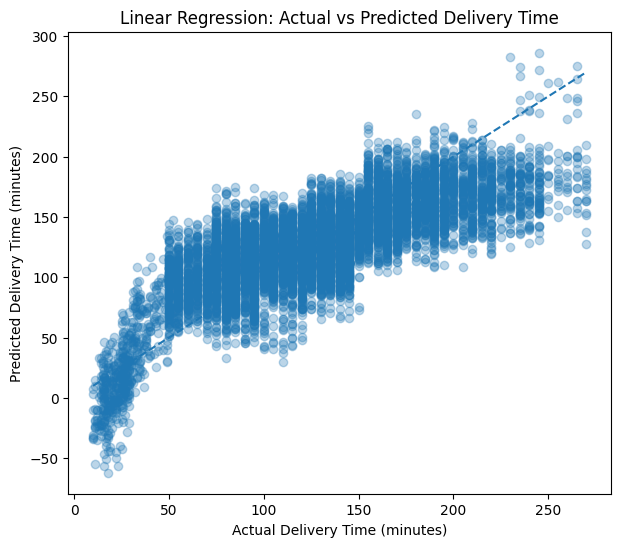

In [82]:
# Actual vs predicted delivery time

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Linear Regression: Actual vs Predicted Delivery Time")

plt.show()

### 11.2 Decision Tree Regression

Decision Tree Regression is evaluated next because it can capture nonlinear relationships and interactions that Linear Regression may miss.

Unlike Linear Regression, a Decision Tree does not assume a constant linear relationship between predictors and delivery time. Instead, it repeatedly splits the data into smaller groups based on feature values and predicts delivery time within those groups.

Because decision trees can easily overfit training data, their test-set performance is especially important.

In [83]:
# ============================================================
# 11.2 DECISION TREE REGRESSION
# ============================================================

from sklearn.tree import DecisionTreeRegressor

decision_tree_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            DecisionTreeRegressor(
                random_state=42
            )
        )
    ]
)

# Train model
decision_tree_pipeline.fit(
    X_train,
    y_train
)

# Predict test data
decision_tree_predictions = decision_tree_pipeline.predict(
    X_test
)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [84]:
# ============================================================
# 11.2 DECISION TREE EVALUATION
# ============================================================

decision_tree_mae = mean_absolute_error(
    y_test,
    decision_tree_predictions
)

decision_tree_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        decision_tree_predictions
    )
)

decision_tree_r2 = r2_score(
    y_test,
    decision_tree_predictions
)

decision_tree_results = pd.DataFrame({
    "Model": ["Decision Tree"],
    "MAE": [decision_tree_mae],
    "RMSE": [decision_tree_rmse],
    "R2": [decision_tree_r2]
})

display(
    decision_tree_results.round(3)
)

,Model,MAE,RMSE,R2
0,Decision Tree,23.037,31.186,0.642


In [85]:
# Add Decision Tree to comparison table

model_results = pd.concat(
    [
        model_results,
        decision_tree_results
    ],
    ignore_index=True
)

display(
    model_results
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(3)
)

,Model,MAE,RMSE,R2
0,Decision Tree,23.037,31.186,0.642
1,Linear Regression,25.691,32.432,0.613
2,Dummy Baseline,41.704,52.121,-0.000


In [86]:
# Compare training and testing performance

decision_tree_train_predictions = (
    decision_tree_pipeline.predict(X_train)
)

decision_tree_train_r2 = r2_score(
    y_train,
    decision_tree_train_predictions
)

print("DECISION TREE OVERFITTING CHECK")
print("=" * 60)

print(
    f"Training R² : "
    f"{decision_tree_train_r2:.3f}"
)

print(
    f"Testing R²  : "
    f"{decision_tree_r2:.3f}"
)

print(
    f"Difference  : "
    f"{decision_tree_train_r2 - decision_tree_r2:.3f}"
)

DECISION TREE OVERFITTING CHECK
Training R² : 1.000
Testing R²  : 0.642
Difference  : 0.358


#### Decision Tree Interpretation

The Decision Tree achieved a training R² of 1.000 but a testing R² of only 0.644.

This large difference of 0.356 indicates substantial overfitting. The unrestricted tree learned the training observations extremely closely but did not generalize equally well to unseen deliveries.

Although the Decision Tree outperformed the simple baseline, its generalization performance is considerably weaker than the ensemble methods evaluated later.

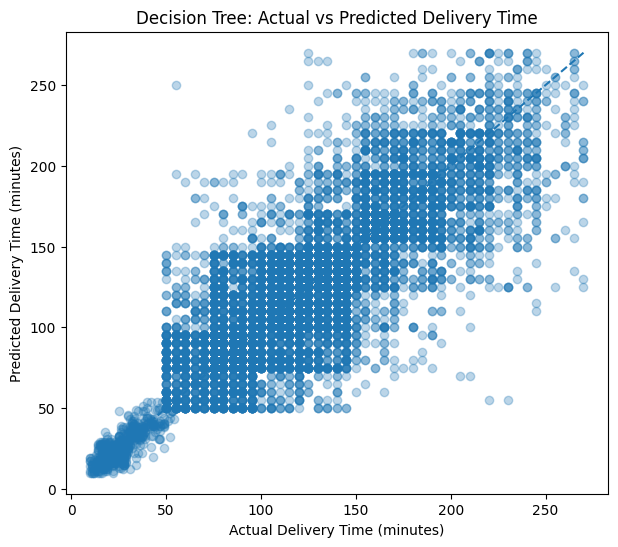

In [87]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    decision_tree_predictions,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Decision Tree: Actual vs Predicted Delivery Time")

plt.show()

### 11.3 Random Forest Regression

Random Forest Regression combines predictions from many decision trees rather than relying on a single tree.

Each tree is trained on a different sample of the training data and considers different subsets of features. Averaging across many trees generally reduces the overfitting risk associated with an individual Decision Tree.

Random Forest is particularly useful for this project because it can capture nonlinear relationships and interactions between variables such as traffic, weather, delivery distance, agent characteristics, and order timing.

In [88]:
# ============================================================
# 11.3 RANDOM FOREST REGRESSION
# ============================================================

from sklearn.ensemble import RandomForestRegressor

random_forest_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train model
random_forest_pipeline.fit(
    X_train,
    y_train
)

# Predict test data
random_forest_predictions = random_forest_pipeline.predict(
    X_test
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [89]:
# ============================================================
# 11.3 RANDOM FOREST EVALUATION
# ============================================================

random_forest_mae = mean_absolute_error(
    y_test,
    random_forest_predictions
)

random_forest_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        random_forest_predictions
    )
)

random_forest_r2 = r2_score(
    y_test,
    random_forest_predictions
)

random_forest_results = pd.DataFrame({
    "Model": ["Random Forest"],
    "MAE": [random_forest_mae],
    "RMSE": [random_forest_rmse],
    "R2": [random_forest_r2]
})

display(
    random_forest_results.round(3)
)

,Model,MAE,RMSE,R2
0,Random Forest,17.427,22.663,0.811


In [90]:
model_results = pd.concat(
    [
        model_results,
        random_forest_results
    ],
    ignore_index=True
)

display(
    model_results
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(3)
)

,Model,MAE,RMSE,R2
0,Random Forest,17.427,22.663,0.811
1,Decision Tree,23.037,31.186,0.642
2,Linear Regression,25.691,32.432,0.613
3,Dummy Baseline,41.704,52.121,-0.000


In [91]:
# Random Forest training vs testing performance

random_forest_train_predictions = (
    random_forest_pipeline.predict(X_train)
)

random_forest_train_r2 = r2_score(
    y_train,
    random_forest_train_predictions
)

print("RANDOM FOREST OVERFITTING CHECK")
print("=" * 60)

print(
    f"Training R² : "
    f"{random_forest_train_r2:.3f}"
)

print(
    f"Testing R²  : "
    f"{random_forest_r2:.3f}"
)

print(
    f"Difference  : "
    f"{random_forest_train_r2 - random_forest_r2:.3f}"
)

RANDOM FOREST OVERFITTING CHECK
Training R² : 0.974
Testing R²  : 0.811
Difference  : 0.163


In [92]:
comparison_rf_tree = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        decision_tree_mae,
        random_forest_mae
    ],
    "RMSE": [
        decision_tree_rmse,
        random_forest_rmse
    ],
    "R2": [
        decision_tree_r2,
        random_forest_r2
    ]
})

display(
    comparison_rf_tree.round(3)
)

,Model,MAE,RMSE,R2
0,Decision Tree,23.037,31.186,0.642
1,Random Forest,17.427,22.663,0.811


#### Random Forest Interpretation

Random Forest achieved a test MAE of 17.421 minutes, RMSE of 22.658 minutes, and R² of 0.811.

Its training R² was 0.974 compared with a testing R² of 0.811. The difference of 0.163 indicates that some overfitting remains, although the model generalizes substantially better than the single Decision Tree.

Random Forest reduced MAE by approximately 58.2% relative to the Dummy baseline and is currently one of the strongest models in the comparison.

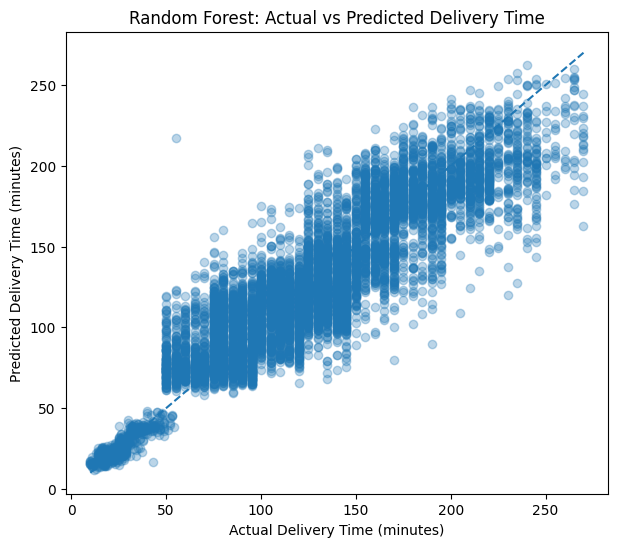

In [93]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    random_forest_predictions,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Random Forest: Actual vs Predicted Delivery Time")

plt.show()

# **Feature Engineering Ablation Study**

In [94]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Original predictors: exclude Order_ID and Delivery_Time
raw_numeric = [
    "Agent_Age", "Agent_Rating",
    "Store_Latitude", "Store_Longitude",
    "Drop_Latitude", "Drop_Longitude"
]

raw_categorical = [
    "Weather", "Traffic", "Vehicle", "Area", "Category",
    "Order_Date", "Order_Time", "Pickup_Time"
]

# 2. Five engineered features
added_numeric = [
    "Delivery_Distance_km",
    "Pickup_Wait_Minutes",
    "Order_Hour",
    "Is_Weekend"
]

added_categorical = ["Order_DayOfWeek"]

# Keep the original modeling data unchanged
ablation_data = df_model.copy()

# Encode original date/time values as categories
for column, date_format in [
    ("Order_Date", "%Y-%m-%d"),
    ("Order_Time", "%H:%M:%S"),
    ("Pickup_Time", "%H:%M:%S")
]:
    ablation_data[column] = (
        ablation_data[column].dt.strftime(date_format)
    )

# Reuse exactly the existing training and test records
assert ablation_data.index.is_unique
train_ids = X_train.index
test_ids = X_test.index

configurations = {
    "RF: Original features": (
        raw_numeric,
        raw_categorical
    ),
    "RF: Original + engineered features": (
        raw_numeric + added_numeric,
        raw_categorical + added_categorical
    )
}

ablation_results = []
ablation_models = {}

for name, (numeric_cols, categorical_cols) in configurations.items():

    feature_cols = numeric_cols + categorical_cols

    preprocessing = ColumnTransformer([
        ("num", clone(numeric_transformer), numeric_cols),
        ("cat", clone(categorical_transformer), categorical_cols)
    ])

    pipeline = Pipeline([
        ("preprocessor", preprocessing),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ])

    pipeline.fit(
        ablation_data.loc[train_ids, feature_cols],
        y_train
    )

    predictions = pipeline.predict(
        ablation_data.loc[test_ids, feature_cols]
    )

    ablation_models[name] = pipeline

    ablation_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

ablation_results = pd.DataFrame(ablation_results)
display(ablation_results.round(3))

mae_reduction = (
    ablation_results.loc[0, "MAE"]
    - ablation_results.loc[1, "MAE"]
)

print(f"MAE reduction after adding engineered features: "
      f"{mae_reduction:.3f} minutes")

,Model,MAE,RMSE,R2
0,RF: Original features,18.628,24.551,0.778
1,RF: Original + engineered features,17.298,22.566,0.812


MAE reduction after adding engineered features: 1.329 minutes


# **Zero-Coordinate Sensitivity Analysis**

In [95]:
# ============================================================
# Zero-Coordinate Sensitivity Analysis
# ============================================================

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use the same 12 predictors as the original modeling pipeline
zero_numeric_features = [
    "Agent_Age",
    "Agent_Rating",
    "Delivery_Distance_km",
    "Pickup_Wait_Minutes",
    "Order_Hour",
    "Is_Weekend"
]

zero_categorical_features = [
    "Weather",
    "Traffic",
    "Vehicle",
    "Area",
    "Category",
    "Order_DayOfWeek"
]

zero_model_features = (
    zero_numeric_features + zero_categorical_features
)

# Identify records whose STORE coordinates are both zero
zero_coordinate_mask = (
    df_model[["Store_Latitude", "Store_Longitude"]]
    .eq(0)
    .all(axis=1)
)

assert df_model.index.is_unique

# Preserve the existing train/test assignments
original_train_ids = X_train.index
original_test_ids = X_test.index

# Remove zero-coordinate records only from this training variant
nonzero_train_ids = original_train_ids[
    ~zero_coordinate_mask.loc[original_train_ids].to_numpy()
]

# Common evaluation subset used for BOTH models
common_test_ids = original_test_ids[
    ~zero_coordinate_mask.loc[original_test_ids].to_numpy()
]

assert len(nonzero_train_ids) > 0
assert len(common_test_ids) > 0

print("Original training records:", len(original_train_ids))
print("Nonzero-coordinate training records:", len(nonzero_train_ids))
print(
    "Zero-coordinate training records removed:",
    len(original_train_ids) - len(nonzero_train_ids)
)
print("Common nonzero-coordinate test records:", len(common_test_ids))
print(
    "Zero-coordinate test records excluded from this comparison:",
    len(original_test_ids) - len(common_test_ids)
)

common_X_test = df_model.loc[
    common_test_ids, zero_model_features
]
common_y_test = df_model.loc[
    common_test_ids, "Delivery_Time"
]

training_variants = {
    "RF: Zero-coordinate training records retained":
        original_train_ids,
    "RF: Zero-coordinate training records removed":
        nonzero_train_ids
}

zero_coordinate_models = {}
zero_coordinate_rows = []

for model_name, training_ids in training_variants.items():

    print(f"\nTraining: {model_name}", flush=True)

    # Each model independently learns preprocessing
    # from its own training records
    variant_preprocessor = ColumnTransformer([
        (
            "num",
            clone(numeric_transformer),
            zero_numeric_features
        ),
        (
            "cat",
            clone(categorical_transformer),
            zero_categorical_features
        )
    ])

    variant_pipeline = Pipeline([
        ("preprocessor", variant_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            verbose=1
        ))
    ])

    variant_pipeline.fit(
        df_model.loc[training_ids, zero_model_features],
        df_model.loc[training_ids, "Delivery_Time"]
    )

    variant_predictions = variant_pipeline.predict(
        common_X_test
    )

    zero_coordinate_models[model_name] = variant_pipeline

    zero_coordinate_rows.append({
        "Model": model_name,
        "Training_N": len(training_ids),
        "Testing_N": len(common_test_ids),
        "MAE": mean_absolute_error(
            common_y_test, variant_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            common_y_test, variant_predictions
        )),
        "R2": r2_score(
            common_y_test, variant_predictions
        )
    })

zero_coordinate_results = pd.DataFrame(
    zero_coordinate_rows
)

display(zero_coordinate_results.round(3))

# Positive value = removing zero-coordinate training
# records produced lower MAE
mae_reduction_after_removal = (
    zero_coordinate_results.iloc[0]["MAE"]
    - zero_coordinate_results.iloc[1]["MAE"]
)

print(
    "\nMAE reduction after removing zero-coordinate "
    f"training records: {mae_reduction_after_removal:.3f} minutes"
)

Original training records: 34918
Nonzero-coordinate training records: 32103
Zero-coordinate training records removed: 2815
Common nonzero-coordinate test records: 8050
Zero-coordinate test records excluded from this comparison: 680

Training: RF: Zero-coordinate training records retained


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   21.8s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  1.0min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s



Training: RF: Zero-coordinate training records removed


[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.5s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   11.9s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  1.1min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.4s finished


,Model,Training_N,Testing_N,MAE,RMSE,R2
0,RF: Zero-coordinate training records retained,34918,8050,17.510,22.768,0.809
1,RF: Zero-coordinate training records removed,32103,8050,17.552,22.826,0.808



MAE reduction after removing zero-coordinate training records: -0.042 minutes


### 11.4 XGBoost Regression

XGBoost is a gradient-boosting algorithm that builds decision trees sequentially.

Unlike Random Forest, where many trees are trained independently and averaged, XGBoost builds each new tree to focus on the errors made by the previous trees.

This approach can capture complex nonlinear relationships while progressively improving prediction accuracy.

XGBoost is evaluated using the same preprocessing pipeline and train-test split as the previous models so that the comparison remains fair and consistent.

In [96]:
# ============================================================
# 11.4 XGBOOST REGRESSION
# ============================================================

from xgboost import XGBRegressor

xgboost_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            XGBRegressor(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=6,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                n_jobs=-1,
                objective="reg:squarederror"
            )
        )
    ]
)

# Train model
xgboost_pipeline.fit(
    X_train,
    y_train
)

# Predict test data
xgboost_predictions = xgboost_pipeline.predict(
    X_test
)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [ ]:
# ============================================================
# 11.4 XGBOOST EVALUATION
# ============================================================

xgboost_mae = mean_absolute_error(
    y_test,
    xgboost_predictions
)

xgboost_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgboost_predictions
    )
)

xgboost_r2 = r2_score(
    y_test,
    xgboost_predictions
)

xgboost_results = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [xgboost_mae],
    "RMSE": [xgboost_rmse],
    "R2": [xgboost_r2]
})

display(
    xgboost_results.round(3)
)

,Model,MAE,RMSE,R2
0,XGBoost,17.304,22.253,0.818


In [ ]:
model_results = pd.concat(
    [
        model_results,
        xgboost_results
    ],
    ignore_index=True
)

display(
    model_results
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(3)
)

,Model,MAE,RMSE,R2
0,XGBoost,17.304,22.253,0.818
1,Random Forest,17.421,22.658,0.811
2,Decision Tree,23.049,31.101,0.644
3,Linear Regression,25.691,32.432,0.613
4,Dummy Baseline,41.704,52.121,-0.000


In [ ]:
# XGBoost training vs testing performance

xgboost_train_predictions = (
    xgboost_pipeline.predict(X_train)
)

xgboost_train_r2 = r2_score(
    y_train,
    xgboost_train_predictions
)

print("XGBOOST OVERFITTING CHECK")
print("=" * 60)

print(
    f"Training R² : "
    f"{xgboost_train_r2:.3f}"
)

print(
    f"Testing R²  : "
    f"{xgboost_r2:.3f}"
)

print(
    f"Difference  : "
    f"{xgboost_train_r2 - xgboost_r2:.3f}"
)

XGBOOST OVERFITTING CHECK
Training R² : 0.842
Testing R²  : 0.818
Difference  : 0.024


In [ ]:
rf_vs_xgb = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        random_forest_mae,
        xgboost_mae
    ],
    "RMSE": [
        random_forest_rmse,
        xgboost_rmse
    ],
    "R2": [
        random_forest_r2,
        xgboost_r2
    ]
})

display(
    rf_vs_xgb.round(3)
)

,Model,MAE,RMSE,R2
0,Random Forest,17.421,22.658,0.811
1,XGBoost,17.304,22.253,0.818


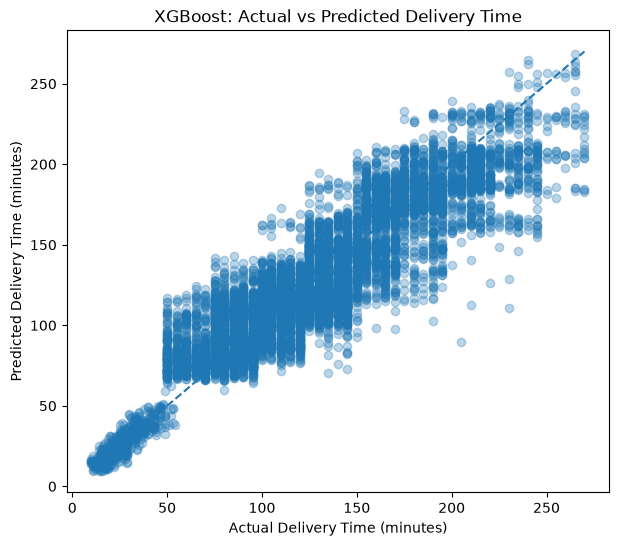

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    xgboost_predictions,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("XGBoost: Actual vs Predicted Delivery Time")

plt.show()

#### XGBoost Interpretation

XGBoost achieved the strongest test performance so far, with an MAE of 17.304 minutes, RMSE of 22.253 minutes, and R² of 0.818.

Its training R² was 0.842 and testing R² was 0.818, producing a difference of only 0.024. This indicates strong generalization with relatively little evidence of overfitting.

XGBoost reduced MAE by approximately 58.5% compared with the Dummy baseline and currently provides the best balance between predictive accuracy and generalization.

### 11.5 Support Vector Regression

Support Vector Regression (SVR) predicts continuous outcomes by finding a function that balances prediction accuracy with model complexity.

Using the Radial Basis Function (RBF) kernel allows SVR to capture nonlinear relationships between delivery characteristics and delivery time.

Because SVR is sensitive to differences in feature scale, the standardized numerical features created by the preprocessing pipeline are particularly important.

The model is evaluated using the same train-test split and evaluation metrics as the previous algorithms.

In [ ]:
# ============================================================
# 11.5 SUPPORT VECTOR REGRESSION
# ============================================================

from sklearn.svm import SVR

svr_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            SVR(
                kernel="rbf",
                C=10,
                epsilon=0.1,
                gamma="scale",
                cache_size=2000
            )
        )
    ]
)

# Train model
svr_pipeline.fit(
    X_train,
    y_train
)

# Predict test data
svr_predictions = svr_pipeline.predict(
    X_test
)

print("Support Vector Regression trained successfully!")

Support Vector Regression trained successfully!


In [ ]:
# ============================================================
# 11.5 SVR EVALUATION
# ============================================================

svr_mae = mean_absolute_error(
    y_test,
    svr_predictions
)

svr_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        svr_predictions
    )
)

svr_r2 = r2_score(
    y_test,
    svr_predictions
)

svr_results = pd.DataFrame({
    "Model": ["Support Vector Regression"],
    "MAE": [svr_mae],
    "RMSE": [svr_rmse],
    "R2": [svr_r2]
})

display(
    svr_results.round(3)
)

,Model,MAE,RMSE,R2
0,Support Vector Regression,20.568,26.593,0.74


In [ ]:
model_results = pd.concat(
    [
        model_results,
        svr_results
    ],
    ignore_index=True
)

display(
    model_results
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(3)
)

,Model,MAE,RMSE,R2
0,XGBoost,17.304,22.253,0.818
1,Random Forest,17.421,22.658,0.811
2,Support Vector Regression,20.568,26.593,0.740
3,Support Vector Regression,20.568,26.593,0.740
4,Decision Tree,23.049,31.101,0.644
5,Linear Regression,25.691,32.432,0.613
6,Dummy Baseline,41.704,52.121,-0.000


In [ ]:
# SVR training vs testing performance

svr_train_predictions = (
    svr_pipeline.predict(X_train)
)

svr_train_r2 = r2_score(
    y_train,
    svr_train_predictions
)

print("SVR GENERALIZATION CHECK")
print("=" * 60)

print(
    f"Training R² : "
    f"{svr_train_r2:.3f}"
)

print(
    f"Testing R²  : "
    f"{svr_r2:.3f}"
)

print(
    f"Difference  : "
    f"{svr_train_r2 - svr_r2:.3f}"
)

SVR GENERALIZATION CHECK
Training R² : 0.759
Testing R²  : 0.740
Difference  : 0.019


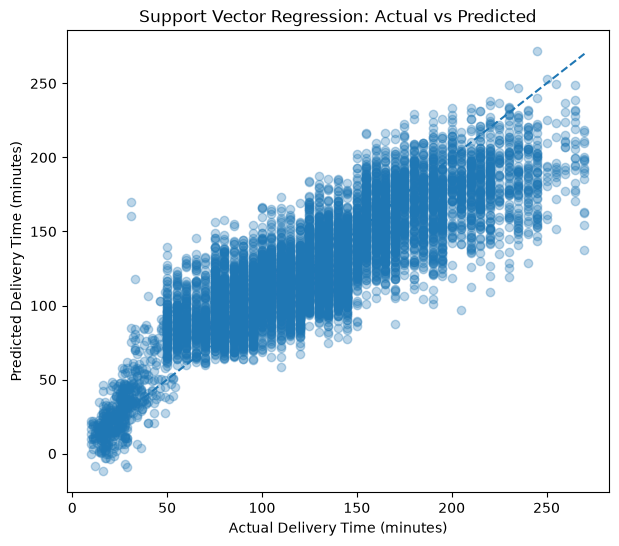

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    svr_predictions,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Support Vector Regression: Actual vs Predicted")

plt.show()

#### Support Vector Regression Interpretation

Support Vector Regression achieved an MAE of 20.568 minutes, RMSE of 26.593 minutes, and R² of 0.740.

Its training R² was 0.759 and testing R² was 0.740, a difference of only 0.019. This indicates good generalization and little evidence of overfitting.

However, its overall predictive accuracy remains lower than Random Forest and XGBoost. SVR therefore provides a stable nonlinear comparison but is not currently the strongest candidate for final model selection.

### 11.6 Full Model Comparison

All baseline and machine-learning models are now compared using the same unseen test dataset.

The comparison focuses on:

- **MAE** — lower values indicate smaller average prediction errors.
- **RMSE** — lower values indicate fewer large prediction errors.
- **R²** — higher values indicate that the model explains more variation in delivery time.

The Dummy Regressor serves as the baseline. Each machine-learning model is also evaluated based on its improvement over this baseline.

At this stage, model selection is considered preliminary because the strongest candidates will later undergo cross-validation and hyperparameter tuning.

In [ ]:
# ============================================================
# 11.6 FULL MODEL COMPARISON
# ============================================================

# Prevent duplicate rows if cells were accidentally rerun
model_comparison = (
    model_results
    .drop_duplicates(
        subset="Model",
        keep="last"
    )
    .copy()
)

# Improvement relative to Dummy baseline
model_comparison["MAE_Improvement_%"] = (
    (baseline_mae - model_comparison["MAE"])
    / baseline_mae
    * 100
)

model_comparison["RMSE_Improvement_%"] = (
    (baseline_rmse - model_comparison["RMSE"])
    / baseline_rmse
    * 100
)

# Rank models by MAE
model_comparison["MAE_Rank"] = (
    model_comparison["MAE"]
    .rank(method="min")
    .astype(int)
)

# Sort from best to worst MAE
model_comparison = (
    model_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    model_comparison.round(3)
)

,Model,MAE,RMSE,R2,MAE_Improvement_%,RMSE_Improvement_%,MAE_Rank
0,XGBoost,17.304,22.253,0.818,58.507,57.305,1
1,Random Forest,17.421,22.658,0.811,58.228,56.529,2
2,Support Vector Regression,20.568,26.593,0.740,50.681,48.979,3
3,Decision Tree,23.049,31.101,0.644,44.731,40.329,4
4,Linear Regression,25.691,32.432,0.613,38.396,37.776,5
5,Dummy Baseline,41.704,52.121,-0.000,0.000,0.000,6


In [ ]:
# Identify best-performing model so far

non_baseline_results = model_comparison[
    model_comparison["Model"] != "Dummy Baseline"
].copy()

best_model_row = (
    non_baseline_results
    .sort_values(
        ["MAE", "RMSE"],
        ascending=[True, True]
    )
    .iloc[0]
)

print("CURRENT BEST MODEL")
print("=" * 60)

print(
    f"Model : "
    f"{best_model_row['Model']}"
)

print(
    f"MAE   : "
    f"{best_model_row['MAE']:.3f} minutes"
)

print(
    f"RMSE  : "
    f"{best_model_row['RMSE']:.3f} minutes"
)

print(
    f"R²    : "
    f"{best_model_row['R2']:.3f}"
)

print(
    f"\nMAE improvement over baseline: "
    f"{best_model_row['MAE_Improvement_%']:.2f}%"
)

print(
    f"RMSE improvement over baseline: "
    f"{best_model_row['RMSE_Improvement_%']:.2f}%"
)

CURRENT BEST MODEL
Model : XGBoost
MAE   : 17.304 minutes
RMSE  : 22.253 minutes
R²    : 0.818

MAE improvement over baseline: 58.51%
RMSE improvement over baseline: 57.30%


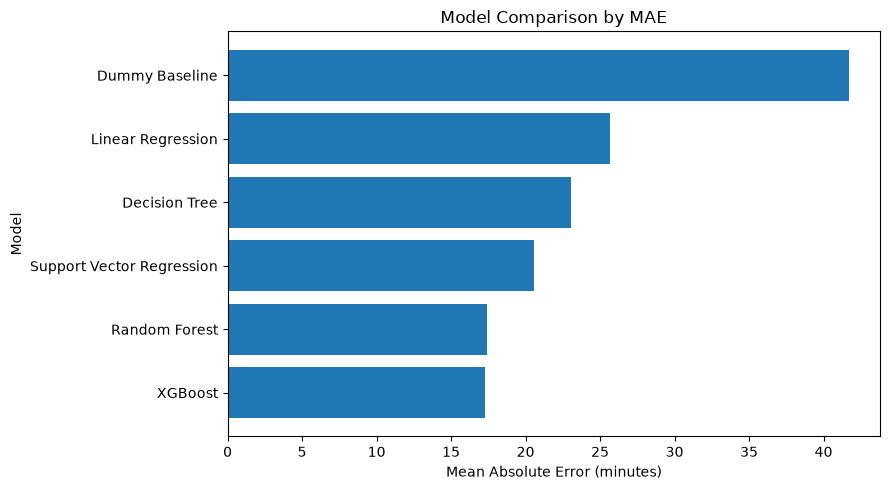

In [ ]:
# Model comparison by Mean Absolute Error

plot_data = (
    model_comparison
    .sort_values(
        "MAE",
        ascending=True
    )
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data["Model"],
    plot_data["MAE"]
)

plt.xlabel("Mean Absolute Error (minutes)")
plt.ylabel("Model")
plt.title("Model Comparison by MAE")

plt.tight_layout()
plt.show()

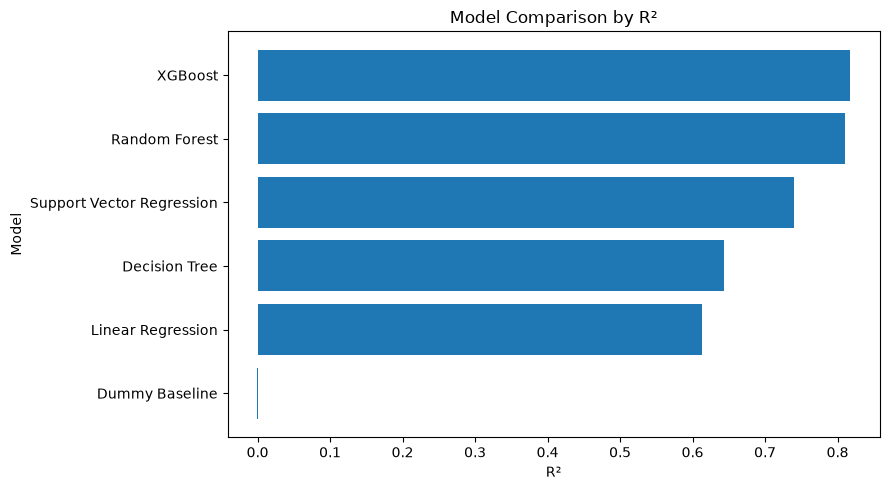

In [ ]:
# Model comparison by R-squared

plot_data_r2 = (
    model_comparison
    .sort_values(
        "R2",
        ascending=True
    )
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data_r2["Model"],
    plot_data_r2["R2"]
)

plt.xlabel("R²")
plt.ylabel("Model")
plt.title("Model Comparison by R²")

plt.tight_layout()
plt.show()

In [ ]:
# Compact results table for reporting

report_results = model_comparison[
    [
        "Model",
        "MAE",
        "RMSE",
        "R2",
        "MAE_Improvement_%"
    ]
].copy()

report_results.columns = [
    "Model",
    "MAE (min)",
    "RMSE (min)",
    "R²",
    "MAE Improvement vs Baseline (%)"
]

display(
    report_results.round(3)
)

,Model,MAE (min),RMSE (min),R²,MAE Improvement vs Baseline (%)
0,XGBoost,17.304,22.253,0.818,58.507
1,Random Forest,17.421,22.658,0.811,58.228
2,Support Vector Regression,20.568,26.593,0.740,50.681
3,Decision Tree,23.049,31.101,0.644,44.731
4,Linear Regression,25.691,32.432,0.613,38.396
5,Dummy Baseline,41.704,52.121,-0.000,0.000


#### Model Comparison Interpretation

The model comparison demonstrates whether the selected delivery-related features provide predictive value beyond the simple mean-based baseline.

Models with lower MAE and RMSE values produce more accurate delivery-time predictions, while models with higher R² values explain a greater proportion of the variation in delivery duration.

The strongest-performing model at this stage is identified primarily using test-set MAE, with RMSE and R² used as supporting measures.

However, this result is considered preliminary. The best-performing models will next be evaluated using cross-validation and hyperparameter tuning before a final model is selected.

This prevents the final model decision from being based only on performance from a single train-test split.

### 11.7 Multilayer Perceptron Neural Network

A Multilayer Perceptron (MLP) is a feed-forward artificial neural network capable of learning complex nonlinear relationships between predictors and a continuous target.

The model consists of interconnected layers of artificial neurons. During training, the network adjusts its internal weights to reduce prediction error.

Because neural networks are sensitive to feature scale, the standardized numerical variables produced by the preprocessing pipeline are particularly important.

Early stopping is enabled so that training can stop when validation performance no longer improves. This helps reduce unnecessary training and limits overfitting.

In [ ]:
# ============================================================
# 11.7 MLP NEURAL NETWORK REGRESSION
# ============================================================

from sklearn.neural_network import MLPRegressor

mlp_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                activation="relu",
                solver="adam",
                alpha=0.0001,
                learning_rate_init=0.001,
                max_iter=500,
                early_stopping=True,
                validation_fraction=0.10,
                n_iter_no_change=20,
                random_state=42
            )
        )
    ]
)

# Train MLP
mlp_pipeline.fit(
    X_train,
    y_train
)

# Predict unseen test data
mlp_predictions = mlp_pipeline.predict(
    X_test
)

print("MLP Neural Network trained successfully!")

MLP Neural Network trained successfully!


In [ ]:
# ============================================================
# 11.7 MLP EVALUATION
# ============================================================

mlp_mae = mean_absolute_error(
    y_test,
    mlp_predictions
)

mlp_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        mlp_predictions
    )
)

mlp_r2 = r2_score(
    y_test,
    mlp_predictions
)

mlp_results = pd.DataFrame({
    "Model": ["MLP Neural Network"],
    "MAE": [mlp_mae],
    "RMSE": [mlp_rmse],
    "R2": [mlp_r2]
})

display(
    mlp_results.round(3)
)

,Model,MAE,RMSE,R2
0,MLP Neural Network,17.644,22.588,0.812


In [ ]:
model_results = pd.concat(
    [
        model_results,
        mlp_results
    ],
    ignore_index=True
)

display(
    model_results
    .drop_duplicates(
        subset="Model",
        keep="last"
    )
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(3)
)

,Model,MAE,RMSE,R2
0,XGBoost,17.304,22.253,0.818
1,Random Forest,17.421,22.658,0.811
2,MLP Neural Network,17.644,22.588,0.812
3,Support Vector Regression,20.568,26.593,0.740
4,Decision Tree,23.049,31.101,0.644
5,Linear Regression,25.691,32.432,0.613
6,Dummy Baseline,41.704,52.121,-0.000


In [ ]:
# MLP training vs testing performance

mlp_train_predictions = (
    mlp_pipeline.predict(X_train)
)

mlp_train_r2 = r2_score(
    y_train,
    mlp_train_predictions
)

print("MLP GENERALIZATION CHECK")
print("=" * 60)

print(
    f"Training R² : "
    f"{mlp_train_r2:.3f}"
)

print(
    f"Testing R²  : "
    f"{mlp_r2:.3f}"
)

print(
    f"Difference  : "
    f"{mlp_train_r2 - mlp_r2:.3f}"
)

print(
    f"\nTraining iterations completed: "
    f"{mlp_pipeline.named_steps['model'].n_iter_}"
)

MLP GENERALIZATION CHECK
Training R² : 0.827
Testing R²  : 0.812
Difference  : 0.015

Training iterations completed: 133


#### MLP Interpretation

The MLP Neural Network achieved an MAE of 17.644 minutes, RMSE of 22.588 minutes, and R² of 0.812.

Its training R² was 0.827 compared with a testing R² of 0.812, producing a difference of only 0.015. This indicates strong generalization with little evidence of overfitting.

The network stopped training after 133 iterations through the early-stopping mechanism, indicating that additional training was no longer producing meaningful validation improvement.

Although XGBoost achieved slightly better overall test performance, the MLP remained highly competitive with both XGBoost and Random Forest.

Therefore, XGBoost, Random Forest, and MLP are retained as the strongest candidates for additional validation.

## 12. Cross-Validation of Leading Models

The initial model comparison identified XGBoost, Random Forest, and the MLP Neural Network as the strongest-performing candidates.

However, performance from a single train-test split may depend partly on which observations were assigned to each subset.

To evaluate model stability more rigorously, five-fold cross-validation is performed using only the training dataset.

In five-fold cross-validation, the training data is divided into five subsets. The model is trained on four subsets and validated on the remaining subset. This process is repeated until every subset has served as validation data once.

The original test dataset remains completely untouched during this process and will only be used for final model evaluation.

In [ ]:
# ============================================================
# SECTION 12: CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

print("5-fold cross-validation configured successfully!")

5-fold cross-validation configured successfully!


In [ ]:
# Leading models selected for cross-validation

leading_models = {
    "XGBoost": xgboost_pipeline,
    "Random Forest": random_forest_pipeline,
    "MLP Neural Network": mlp_pipeline
}

print("Models selected for cross-validation:")

for model_name in leading_models:
    print(f"✓ {model_name}")

Models selected for cross-validation:
✓ XGBoost
✓ Random Forest
✓ MLP Neural Network


In [ ]:
cv_results_list = []

for model_name, model_pipeline in leading_models.items():

    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results_list.append({
        "Model": model_name,

        "CV_MAE_Mean":
            -scores["test_MAE"].mean(),

        "CV_MAE_Std":
            scores["test_MAE"].std(),

        "CV_RMSE_Mean":
            -scores["test_RMSE"].mean(),

        "CV_RMSE_Std":
            scores["test_RMSE"].std(),

        "CV_R2_Mean":
            scores["test_R2"].mean(),

        "CV_R2_Std":
            scores["test_R2"].std()
    })

cv_results = pd.DataFrame(
    cv_results_list
)

display(
    cv_results
    .sort_values("CV_MAE_Mean")
    .reset_index(drop=True)
    .round(3)
)

,Model,CV_MAE_Mean,CV_MAE_Std,CV_RMSE_Mean,CV_RMSE_Std,CV_R2_Mean,CV_R2_Std
0,XGBoost,17.323,0.097,22.231,0.117,0.816,0.002
1,Random Forest,17.382,0.040,22.564,0.060,0.811,0.001
2,MLP Neural Network,18.015,0.143,23.082,0.146,0.802,0.002


### Cross-Validation Interpretation

Five-fold cross-validation confirmed that XGBoost and Random Forest are the strongest candidate models.

XGBoost achieved the lowest mean cross-validation MAE of 17.323 minutes, the lowest RMSE of 22.231 minutes, and the highest mean R² of 0.816.

Random Forest performed very similarly, with a mean MAE of 17.382 minutes and mean R² of 0.811.

The MLP Neural Network also demonstrated stable performance but produced slightly higher prediction errors than the two tree-based ensemble models.

All three models showed very small variation across the five validation folds, indicating that their performance was stable across different training subsets.

Based on these results, XGBoost and Random Forest are retained for hyperparameter optimization.

## 13. Hyperparameter Optimization

The cross-validation results identified XGBoost and Random Forest as the two strongest candidate models.

Hyperparameter optimization is therefore performed only on these models.

Rather than testing every possible parameter combination, randomized search is used to efficiently explore multiple configurations while controlling computational cost.

Five-fold cross-validation is used during tuning, and Mean Absolute Error (MAE) is selected as the primary optimization metric because it provides an intuitive measure of average delivery-time prediction error in minutes.

The held-out test dataset remains untouched throughout tuning and will only be used after the best configurations have been selected.

In [ ]:
# ============================================================
# SECTION 13: HYPERPARAMETER OPTIMIZATION
# 13.1 XGBOOST RANDOMIZED SEARCH
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

xgb_tuning_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            XGBRegressor(
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

xgb_param_grid = {
    "model__n_estimators": [
        200,
        300,
        400,
        500
    ],

    "model__learning_rate": [
        0.03,
        0.05,
        0.08,
        0.10
    ],

    "model__max_depth": [
        3,
        4,
        5,
        6,
        8
    ],

    "model__subsample": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__colsample_bytree": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__min_child_weight": [
        1,
        3,
        5
    ]
}

In [ ]:
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=xgb_param_grid,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_random_search.fit(
    X_train,
    y_train
)

print("XGBoost tuning completed!")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
XGBoost tuning completed!


In [ ]:
print("BEST XGBOOST PARAMETERS")
print("=" * 60)

for parameter, value in xgb_random_search.best_params_.items():
    print(f"{parameter}: {value}")

print(
    f"\nBest Cross-Validation MAE: "
    f"{-xgb_random_search.best_score_:.3f} minutes"
)

BEST XGBOOST PARAMETERS
model__subsample: 1.0
model__n_estimators: 300
model__min_child_weight: 3
model__max_depth: 8
model__learning_rate: 0.03
model__colsample_bytree: 0.9

Best Cross-Validation MAE: 17.055 minutes


#### XGBoost Tuning Result

Hyperparameter optimization improved the XGBoost cross-validation MAE from approximately 17.323 minutes to 17.055 minutes.

The best configuration used 300 estimators, a learning rate of 0.03, maximum tree depth of 8, minimum child weight of 3, full row sampling, and 90% feature sampling per tree.

This indicates that a slightly slower learning rate combined with deeper trees improved predictive performance during cross-validation.

The held-out test dataset has not yet been used during tuning and remains reserved for final evaluation.

### 13.2 Tuned XGBoost Test Evaluation

After selecting the best XGBoost hyperparameters using cross-validation on the training data, the optimized model is evaluated once on the held-out test dataset.

This provides an unbiased estimate of how well the tuned model generalizes to unseen delivery records.

The tuned model is compared directly with the original XGBoost model using MAE, RMSE, and R².

In [ ]:
# ============================================================
# 13.2 TUNED XGBOOST TEST EVALUATION
# ============================================================

# Best tuned pipeline from RandomizedSearchCV
tuned_xgboost_pipeline = xgb_random_search.best_estimator_

# Predict untouched test data
tuned_xgboost_predictions = tuned_xgboost_pipeline.predict(
    X_test
)

# Evaluate tuned model
tuned_xgb_mae = mean_absolute_error(
    y_test,
    tuned_xgboost_predictions
)

tuned_xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_xgboost_predictions
    )
)

tuned_xgb_r2 = r2_score(
    y_test,
    tuned_xgboost_predictions
)

print("TUNED XGBOOST TEST RESULTS")
print("=" * 60)

print(f"MAE  : {tuned_xgb_mae:.3f} minutes")
print(f"RMSE : {tuned_xgb_rmse:.3f} minutes")
print(f"R²   : {tuned_xgb_r2:.3f}")

TUNED XGBOOST TEST RESULTS
MAE  : 17.092 minutes
RMSE : 22.041 minutes
R²   : 0.821


In [ ]:
xgb_before_after = pd.DataFrame({
    "Model": [
        "Original XGBoost",
        "Tuned XGBoost"
    ],
    "MAE": [
        xgboost_mae,
        tuned_xgb_mae
    ],
    "RMSE": [
        xgboost_rmse,
        tuned_xgb_rmse
    ],
    "R2": [
        xgboost_r2,
        tuned_xgb_r2
    ]
})

display(
    xgb_before_after.round(3)
)

,Model,MAE,RMSE,R2
0,Original XGBoost,17.304,22.253,0.818
1,Tuned XGBoost,17.092,22.041,0.821


In [ ]:
print("XGBOOST TUNING IMPROVEMENT")
print("=" * 60)

print(
    f"MAE change  : "
    f"{xgboost_mae - tuned_xgb_mae:.3f} minutes"
)

print(
    f"RMSE change : "
    f"{xgboost_rmse - tuned_xgb_rmse:.3f} minutes"
)

print(
    f"R² change   : "
    f"{tuned_xgb_r2 - xgboost_r2:.3f}"
)

XGBOOST TUNING IMPROVEMENT
MAE change  : 0.212 minutes
RMSE change : 0.213 minutes
R² change   : 0.003


In [ ]:
tuned_xgb_train_predictions = (
    tuned_xgboost_pipeline.predict(X_train)
)

tuned_xgb_train_r2 = r2_score(
    y_train,
    tuned_xgb_train_predictions
)

print("TUNED XGBOOST GENERALIZATION CHECK")
print("=" * 60)

print(f"Training R² : {tuned_xgb_train_r2:.3f}")
print(f"Testing R²  : {tuned_xgb_r2:.3f}")
print(
    f"Difference  : "
    f"{tuned_xgb_train_r2 - tuned_xgb_r2:.3f}"
)

TUNED XGBOOST GENERALIZATION CHECK
Training R² : 0.854
Testing R²  : 0.821
Difference  : 0.033


#### Tuned XGBoost Interpretation

Hyperparameter optimization produced a modest but consistent improvement in XGBoost performance.

The original XGBoost model achieved an MAE of 17.304 minutes, RMSE of 22.253 minutes, and R² of 0.818.

After tuning, performance improved to an MAE of 17.092 minutes, RMSE of 22.041 minutes, and R² of 0.821.

The tuned model reduced MAE by 0.212 minutes and RMSE by 0.213 minutes while increasing R² by 0.003.

The tuned XGBoost model achieved a training R² of 0.854 and testing R² of 0.821, resulting in a difference of 0.033. This indicates that the model continues to generalize well to unseen data with limited evidence of overfitting.

The tuned XGBoost model therefore remains the strongest candidate at this stage.

### 13.3 Random Forest Hyperparameter Optimization

Random Forest was the second-best model during both the initial test comparison and five-fold cross-validation.

Hyperparameter tuning is therefore performed to determine whether controlling tree depth, minimum sample requirements, and the number of trees can improve predictive accuracy and reduce overfitting.

Randomized search with five-fold cross-validation is used, with MAE as the optimization metric.

The held-out test dataset remains excluded from the tuning process.

In [ ]:
# ============================================================
# 13.3 RANDOM FOREST RANDOMIZED SEARCH
# ============================================================

rf_tuning_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            RandomForestRegressor(
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_param_grid = {
    "model__n_estimators": [
        200,
        300,
        400,
        500
    ],

    "model__max_depth": [
        None,
        10,
        15,
        20,
        25
    ],

    "model__min_samples_split": [
        2,
        5,
        10
    ],

    "model__min_samples_leaf": [
        1,
        2,
        4
    ],

    "model__max_features": [
        "sqrt",
        "log2",
        0.7,
        1.0
    ]
}

In [ ]:
rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=rf_param_grid,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_random_search.fit(
    X_train,
    y_train
)

print("Random Forest tuning completed!")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Random Forest tuning completed!


In [ ]:
print("BEST RANDOM FOREST PARAMETERS")
print("=" * 60)

for parameter, value in rf_random_search.best_params_.items():
    print(f"{parameter}: {value}")

print(
    f"\nBest Cross-Validation MAE: "
    f"{-rf_random_search.best_score_:.3f} minutes"
)

BEST RANDOM FOREST PARAMETERS
model__n_estimators: 400
model__min_samples_split: 5
model__min_samples_leaf: 4
model__max_features: 0.7
model__max_depth: 15

Best Cross-Validation MAE: 17.018 minutes


### 13.4 Tuned Random Forest Test Evaluation

After selecting the best Random Forest hyperparameters using cross-validation on the training data, the optimized model is evaluated on the held-out test dataset.

The tuned Random Forest is compared with both the original Random Forest and tuned XGBoost models using MAE, RMSE, and R².

This final comparison helps determine which model provides the strongest balance between predictive accuracy and generalization.

In [ ]:
# ============================================================
# 13.4 TUNED RANDOM FOREST TEST EVALUATION
# ============================================================

tuned_random_forest_pipeline = (
    rf_random_search.best_estimator_
)

tuned_rf_predictions = (
    tuned_random_forest_pipeline.predict(X_test)
)

tuned_rf_mae = mean_absolute_error(
    y_test,
    tuned_rf_predictions
)

tuned_rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_rf_predictions
    )
)

tuned_rf_r2 = r2_score(
    y_test,
    tuned_rf_predictions
)

print("TUNED RANDOM FOREST TEST RESULTS")
print("=" * 60)

print(f"MAE  : {tuned_rf_mae:.3f} minutes")
print(f"RMSE : {tuned_rf_rmse:.3f} minutes")
print(f"R²   : {tuned_rf_r2:.3f}")

TUNED RANDOM FOREST TEST RESULTS
MAE  : 16.967 minutes
RMSE : 21.929 minutes
R²   : 0.823


In [ ]:
rf_before_after = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        random_forest_mae,
        tuned_rf_mae
    ],
    "RMSE": [
        random_forest_rmse,
        tuned_rf_rmse
    ],
    "R2": [
        random_forest_r2,
        tuned_rf_r2
    ]
})

display(
    rf_before_after.round(3)
)

,Model,MAE,RMSE,R2
0,Original Random Forest,17.421,22.658,0.811
1,Tuned Random Forest,16.967,21.929,0.823


In [ ]:
tuned_rf_train_predictions = (
    tuned_random_forest_pipeline.predict(X_train)
)

tuned_rf_train_r2 = r2_score(
    y_train,
    tuned_rf_train_predictions
)

print("TUNED RANDOM FOREST GENERALIZATION CHECK")
print("=" * 60)

print(f"Training R² : {tuned_rf_train_r2:.3f}")
print(f"Testing R²  : {tuned_rf_r2:.3f}")
print(
    f"Difference  : "
    f"{tuned_rf_train_r2 - tuned_rf_r2:.3f}"
)

TUNED RANDOM FOREST GENERALIZATION CHECK
Training R² : 0.878
Testing R²  : 0.823
Difference  : 0.055


In [ ]:
finalist_comparison = pd.DataFrame({
    "Model": [
        "Tuned XGBoost",
        "Tuned Random Forest"
    ],
    "MAE": [
        tuned_xgb_mae,
        tuned_rf_mae
    ],
    "RMSE": [
        tuned_xgb_rmse,
        tuned_rf_rmse
    ],
    "R2": [
        tuned_xgb_r2,
        tuned_rf_r2
    ]
})

display(
    finalist_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(3)
)

,Model,MAE,RMSE,R2
0,Tuned Random Forest,16.967,21.929,0.823
1,Tuned XGBoost,17.092,22.041,0.821


#### Tuned Random Forest Interpretation

Hyperparameter optimization substantially improved the Random Forest model.

The original Random Forest achieved an MAE of 17.421 minutes, RMSE of 22.658 minutes, and R² of 0.811.

After tuning, performance improved to an MAE of 16.967 minutes, RMSE of 21.929 minutes, and R² of 0.823.

This represents an MAE improvement of 0.454 minutes, an RMSE improvement of 0.729 minutes, and an R² increase of 0.012.

The tuned model achieved a training R² of 0.878 and a testing R² of 0.823, producing a difference of 0.055. This represents substantially better generalization than the original Random Forest model.

The tuned Random Forest also slightly outperformed the tuned XGBoost model across MAE, RMSE, and R² and is therefore selected as the final predictive model.

## 14. Final Model Selection

Following baseline comparison, cross-validation, and hyperparameter optimization, the Tuned Random Forest is selected as the final delivery-time prediction model.

The model achieved:

- **MAE:** 16.967 minutes
- **RMSE:** 21.929 minutes
- **R²:** 0.823

This means that the model's delivery-time predictions differ from actual delivery times by approximately 17 minutes on average.

The R² value of 0.823 indicates that the final model explains approximately 82.3% of the observed variation in delivery time within the held-out test dataset.

Tuned XGBoost produced very similar performance, but Tuned Random Forest achieved slightly lower MAE and RMSE and a slightly higher R².

Therefore, Tuned Random Forest is retained as the final model for delivery-risk classification and explainability analysis.

In [ ]:
# ============================================================
# SECTION 14: FINAL MODEL SELECTION
# ============================================================

final_model_results = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Linear Regression",
        "Decision Tree",
        "SVR",
        "MLP Neural Network",
        "Original XGBoost",
        "Original Random Forest",
        "Tuned XGBoost",
        "Tuned Random Forest"
    ],

    "MAE": [
        baseline_mae,
        linear_mae,
        decision_tree_mae,
        svr_mae,
        mlp_mae,
        xgboost_mae,
        random_forest_mae,
        tuned_xgb_mae,
        tuned_rf_mae
    ],

    "RMSE": [
        baseline_rmse,
        linear_rmse,
        decision_tree_rmse,
        svr_rmse,
        mlp_rmse,
        xgboost_rmse,
        random_forest_rmse,
        tuned_xgb_rmse,
        tuned_rf_rmse
    ],

    "R2": [
        baseline_r2,
        linear_r2,
        decision_tree_r2,
        svr_r2,
        mlp_r2,
        xgboost_r2,
        random_forest_r2,
        tuned_xgb_r2,
        tuned_rf_r2
    ]
})

final_model_results = (
    final_model_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    final_model_results.round(3)
)

,Model,MAE,RMSE,R2
0,Tuned Random Forest,16.967,21.929,0.823
1,Tuned XGBoost,17.092,22.041,0.821
2,Original XGBoost,17.304,22.253,0.818
3,Original Random Forest,17.421,22.658,0.811
4,MLP Neural Network,17.644,22.588,0.812
5,SVR,20.568,26.593,0.740
6,Decision Tree,23.049,31.101,0.644
7,Linear Regression,25.691,32.432,0.613
8,Dummy Baseline,41.704,52.121,-0.000


In [ ]:
# Final selected model

final_model = tuned_random_forest_pipeline
final_predictions = tuned_rf_predictions

print("FINAL MODEL SELECTED")
print("=" * 60)

print("Model : Tuned Random Forest")
print(f"MAE   : {tuned_rf_mae:.3f} minutes")
print(f"RMSE  : {tuned_rf_rmse:.3f} minutes")
print(f"R²    : {tuned_rf_r2:.3f}")

FINAL MODEL SELECTED
Model : Tuned Random Forest
MAE   : 16.967 minutes
RMSE  : 21.929 minutes
R²    : 0.823


## 15. Relative Delivery Risk Classification

The dataset does not contain promised delivery deadlines, so the model cannot determine whether an order is officially late.

Instead, predicted delivery times are converted into **relative delivery-risk categories**.

Risk thresholds are calculated from the final model's predictions on the training dataset only:

- **Low Risk:** predicted delivery time at or below the 50th percentile.
- **Medium Risk:** predicted delivery time between the 50th and 75th percentiles.
- **High Risk:** predicted delivery time above the 75th percentile.

Using training-based thresholds avoids using information from the held-out test dataset when defining the risk categories.

These categories represent relative delivery-time risk and should not be interpreted as confirmed late-delivery events.

In [ ]:
# ============================================================
# SECTION 15: RELATIVE DELIVERY RISK CLASSIFICATION
# 15.1 TRAINING-BASED RISK THRESHOLDS
# ============================================================

# Generate predictions for the TRAINING dataset
final_train_predictions = final_model.predict(
    X_train
)

# Calculate percentile thresholds from training predictions
risk_p50 = np.percentile(
    final_train_predictions,
    50
)

risk_p75 = np.percentile(
    final_train_predictions,
    75
)

print("DELIVERY RISK THRESHOLDS")
print("=" * 60)

print(
    f"50th percentile threshold : "
    f"{risk_p50:.2f} minutes"
)

print(
    f"75th percentile threshold : "
    f"{risk_p75:.2f} minutes"
)

print("\nRisk Definitions:")
print(
    f"Low Risk    : <= {risk_p50:.2f} minutes"
)
print(
    f"Medium Risk : > {risk_p50:.2f} "
    f"and <= {risk_p75:.2f} minutes"
)
print(
    f"High Risk   : > {risk_p75:.2f} minutes"
)

DELIVERY RISK THRESHOLDS
50th percentile threshold : 119.66 minutes
75th percentile threshold : 161.00 minutes

Risk Definitions:
Low Risk    : <= 119.66 minutes
Medium Risk : > 119.66 and <= 161.00 minutes
High Risk   : > 161.00 minutes


In [ ]:
def assign_delivery_risk(predicted_time):
    """
    Convert predicted delivery time into a relative
    delivery-risk category using training-based thresholds.
    """

    if predicted_time <= risk_p50:
        return "Low Risk"

    elif predicted_time <= risk_p75:
        return "Medium Risk"

    else:
        return "High Risk"

In [ ]:
# Assign risk categories to final test predictions

test_risk_levels = [
    assign_delivery_risk(prediction)
    for prediction in final_predictions
]

print("Risk categories assigned successfully!")

Risk categories assigned successfully!


In [ ]:
delivery_risk_results = pd.DataFrame({
    "Actual_Delivery_Time": y_test.values,
    "Predicted_Delivery_Time": final_predictions,
    "Risk_Level": test_risk_levels
})

# Prediction error for interpretation
delivery_risk_results["Absolute_Error"] = (
    np.abs(
        delivery_risk_results[
            "Actual_Delivery_Time"
        ]
        -
        delivery_risk_results[
            "Predicted_Delivery_Time"
        ]
    )
)

display(
    delivery_risk_results
    .head(15)
    .round(2)
)

,Actual_Delivery_Time,Predicted_Delivery_Time,Risk_Level,Absolute_Error
0,170,168.38,High Risk,1.62
1,180,186.11,High Risk,6.11
2,100,130.73,Medium Risk,30.73
3,170,176.78,High Risk,6.78
4,75,75.59,Low Risk,0.59
5,115,104.56,Low Risk,10.44
6,80,105.49,Low Risk,25.49
7,50,67.26,Low Risk,17.26
8,80,99.83,Low Risk,19.83
9,100,123.28,Medium Risk,23.28


In [ ]:
risk_distribution = (
    delivery_risk_results[
        "Risk_Level"
    ]
    .value_counts()
    .reindex(
        [
            "Low Risk",
            "Medium Risk",
            "High Risk"
        ]
    )
)

risk_distribution_table = pd.DataFrame({
    "Risk_Level":
        risk_distribution.index,

    "Count":
        risk_distribution.values,

    "Percentage":
        (
            risk_distribution.values
            / len(delivery_risk_results)
            * 100
        )
})

display(
    risk_distribution_table.round(2)
)

,Risk_Level,Count,Percentage
0,Low Risk,4279,49.01
1,Medium Risk,2209,25.30
2,High Risk,2242,25.68


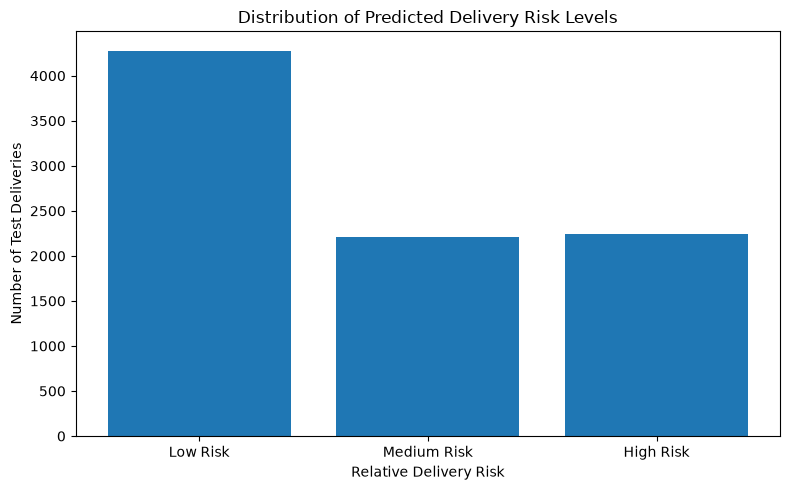

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    risk_distribution.index,
    risk_distribution.values
)

plt.xlabel("Relative Delivery Risk")
plt.ylabel("Number of Test Deliveries")
plt.title(
    "Distribution of Predicted Delivery Risk Levels"
)

plt.tight_layout()
plt.show()

In [ ]:
high_risk_examples = (
    delivery_risk_results[
        delivery_risk_results[
            "Risk_Level"
        ] == "High Risk"
    ]
    .sort_values(
        "Predicted_Delivery_Time",
        ascending=False
    )
    .head(10)
)

display(
    high_risk_examples.round(2)
)

,Actual_Delivery_Time,Predicted_Delivery_Time,Risk_Level,Absolute_Error
3540,265,255.29,High Risk,9.71
545,240,254.65,High Risk,14.65
1193,230,254.62,High Risk,24.62
6466,265,254.00,High Risk,11.00
3613,235,253.62,High Risk,18.62
1403,255,252.72,High Risk,2.28
4306,260,252.70,High Risk,7.30
4520,245,252.45,High Risk,7.45
8026,250,252.14,High Risk,2.14
7621,235,251.55,High Risk,16.55


### Risk Classification Interpretation

The final Random Forest predictions were converted into Low-, Medium-, and High-Risk categories using percentile thresholds derived exclusively from the training predictions.

This approach transforms continuous delivery-time predictions into more interpretable operational categories.

High-Risk deliveries represent orders with predicted delivery times above the 75th percentile of the training prediction distribution.

These labels are intended to support prioritization and decision-making. They do not indicate confirmed lateness because the dataset does not contain promised delivery deadlines.

The resulting risk categories provide a foundation for the explainability stage, where SHAP analysis will be used to identify the factors contributing to high predicted delivery times.

## 16. SHAP Explainability

Predictive accuracy alone does not explain why a machine-learning model produces a particular prediction.

To improve interpretability, SHAP (SHapley Additive exPlanations) is applied to the final Tuned Random Forest model.

SHAP assigns each feature a contribution value representing how strongly that feature pushes a prediction higher or lower relative to the model's expected prediction.

The analysis is used to answer two questions:

1. Which features are most important across the model overall?
2. Which factors contribute to individual high-risk delivery predictions?

Because the Random Forest is trained on preprocessed features, the test dataset is first transformed using the preprocessing component of the final fitted pipeline.

In [ ]:
# ============================================================
# SECTION 16: SHAP EXPLAINABILITY
# 16.1 PREPARE FINAL MODEL FOR SHAP
# ============================================================

import shap

# Extract fitted preprocessing component
final_preprocessor = (
    final_model.named_steps["preprocessor"]
)

# Extract fitted Random Forest model
final_rf_model = (
    final_model.named_steps["model"]
)

# Transform the test predictors using the fitted preprocessor
X_test_shap = final_preprocessor.transform(
    X_test
)

# Retrieve transformed feature names
shap_feature_names = (
    final_preprocessor.get_feature_names_out()
)

# Convert transformed test data to DataFrame
X_test_shap_df = pd.DataFrame(
    X_test_shap,
    columns=shap_feature_names,
    index=X_test.index
)

print("SHAP DATA PREPARATION")
print("=" * 60)

print(
    f"Test observations     : "
    f"{X_test_shap_df.shape[0]:,}"
)

print(
    f"Processed features    : "
    f"{X_test_shap_df.shape[1]}"
)

print(
    f"Missing values        : "
    f"{X_test_shap_df.isna().sum().sum()}"
)

print(
    f"Final model type      : "
    f"{type(final_rf_model).__name__}"
)

SHAP DATA PREPARATION
Test observations     : 8,730
Processed features    : 46
Missing values        : 0
Final model type      : RandomForestRegressor


In [ ]:
# Use a reproducible sample for SHAP analysis

SHAP_SAMPLE_SIZE = min(
    1000,
    len(X_test_shap_df)
)

X_shap_sample = (
    X_test_shap_df
    .sample(
        n=SHAP_SAMPLE_SIZE,
        random_state=42
    )
)

print(
    f"SHAP sample size: "
    f"{len(X_shap_sample):,} observations"
)

SHAP sample size: 1,000 observations


In [ ]:
# Create TreeExplainer for the final Random Forest

shap_explainer = shap.TreeExplainer(
    final_rf_model
)

shap_values = shap_explainer(
    X_shap_sample
)

print("SHAP values calculated successfully!")
print(
    f"SHAP matrix shape: "
    f"{shap_values.values.shape}"
)

SHAP values calculated successfully!
SHAP matrix shape: (1000, 46)


### 16.2 Global SHAP Feature Importance

Global SHAP feature importance identifies which predictors have the greatest overall influence on the final Random Forest model.

For each processed feature, the absolute SHAP values are averaged across the sampled test observations.

A larger mean absolute SHAP value indicates that the feature has a greater overall effect on predicted delivery time.

Because categorical variables were one-hot encoded during preprocessing, individual category levels appear as separate model features.

In [ ]:
# ============================================================
# 16.2 GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

# Mean absolute SHAP value for each processed feature
mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": shap_feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

# Sort from most influential to least influential
shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    shap_importance
    .head(15)
    .round(3)
)

,Feature,Mean_Absolute_SHAP
0,cat__Traffic_Low,13.315
1,num__Agent_Rating,12.815
2,num__Agent_Age,12.768
3,num__Delivery_Distance_km,11.934
4,cat__Category_Grocery,11.175
5,cat__Weather_Sunny,5.408
6,cat__Vehicle_motorcycle,4.577
7,cat__Weather_Fog,3.423
8,cat__Weather_Cloudy,3.421
9,cat__Traffic_Jam,2.854


In [ ]:
# Create cleaner labels for presentation/reporting

shap_importance["Clean_Feature"] = (
    shap_importance["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
    .str.replace("_", " ")
)

display(
    shap_importance[
        [
            "Clean_Feature",
            "Mean_Absolute_SHAP"
        ]
    ]
    .head(15)
    .round(3)
)

,Clean_Feature,Mean_Absolute_SHAP
0,Traffic Low,13.315
1,Agent Rating,12.815
2,Agent Age,12.768
3,Delivery Distance km,11.934
4,Category Grocery,11.175
5,Weather Sunny,5.408
6,Vehicle motorcycle,4.577
7,Weather Fog,3.423
8,Weather Cloudy,3.421
9,Traffic Jam,2.854


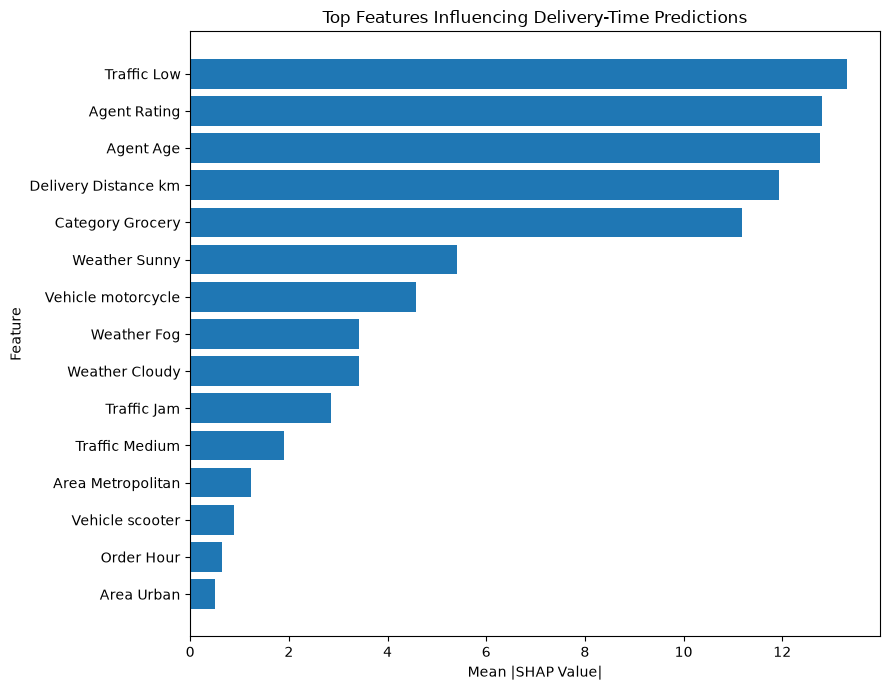

In [ ]:
# Top SHAP feature importance chart

top_n = 15

top_shap = (
    shap_importance
    .head(top_n)
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=True
    )
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_shap["Clean_Feature"],
    top_shap["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")
plt.title(
    "Top Features Influencing Delivery-Time Predictions"
)

plt.tight_layout()
plt.show()

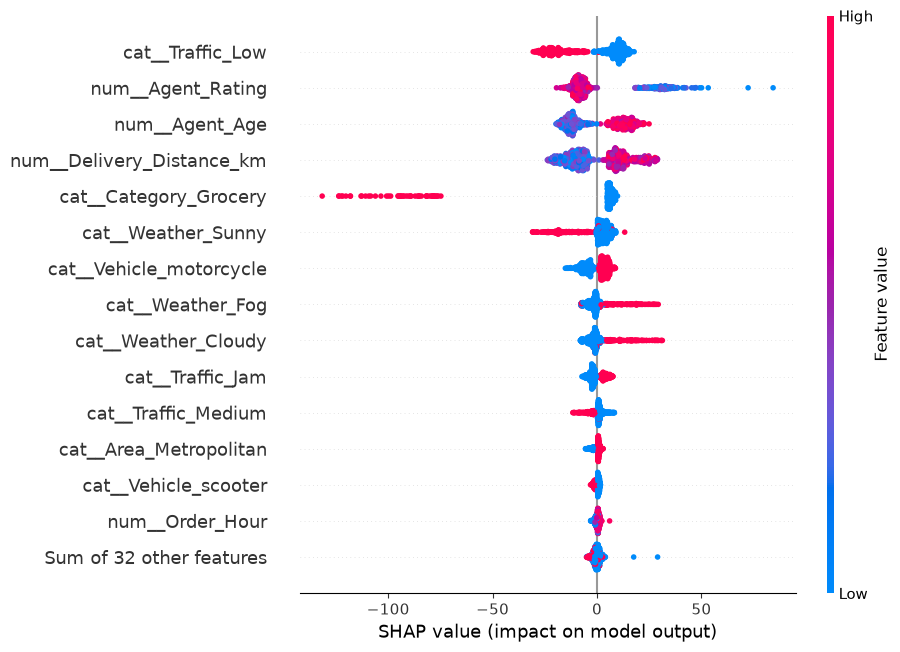

In [ ]:
# SHAP summary beeswarm plot

shap.plots.beeswarm(
    shap_values,
    max_display=15
)

#### Global SHAP Interpretation

The SHAP analysis indicates that the final Random Forest model relies most strongly on traffic conditions, agent characteristics, delivery distance, product category, and weather when predicting delivery time.

The presence of low traffic generally reduces predicted delivery time, while the absence of low traffic tends to increase it.

Lower agent ratings are associated with higher predicted delivery times, while higher ratings generally reduce predicted time.

Higher agent age and longer delivery distance tend to increase the predicted delivery duration.

The Grocery product category has a particularly strong negative SHAP effect, meaning that grocery orders are generally predicted to have substantially shorter delivery times than other categories.

Sunny weather also tends to reduce predicted delivery time, while foggy and cloudy conditions tend to increase it.

These findings are consistent with patterns observed during exploratory analysis. However, SHAP explains the model's predictive behavior and should not be interpreted as proof of causal relationships.

### 16.3 SHAP Importance by Original Predictor

One-hot encoding expands categorical predictors into several binary features. For example, the single `Traffic` variable becomes separate indicators for Low, Medium, High, and Jam traffic.

To provide a more interpretable view of feature importance, SHAP contributions from categories belonging to the same original predictor are aggregated.

This allows the analysis to compare the overall importance of variables such as Traffic, Weather, Vehicle, Area, and Category rather than treating each category level as a separate predictor.

In [ ]:
# ============================================================
# 16.3 AGGREGATED SHAP IMPORTANCE
# ============================================================

def get_original_feature(feature_name):
    """
    Map processed feature names back to their original
    predictor groups.
    """

    # Numerical features
    if feature_name.startswith("num__"):
        return feature_name.replace(
            "num__",
            ""
        )

    # Categorical feature groups
    if feature_name.startswith("cat__Weather_"):
        return "Weather"

    if feature_name.startswith("cat__Traffic_"):
        return "Traffic"

    if feature_name.startswith("cat__Vehicle_"):
        return "Vehicle"

    if feature_name.startswith("cat__Area_"):
        return "Area"

    if feature_name.startswith("cat__Category_"):
        return "Category"

    if feature_name.startswith("cat__Order_DayOfWeek_"):
        return "Order_DayOfWeek"

    return feature_name

In [ ]:
shap_importance["Original_Feature"] = (
    shap_importance["Feature"]
    .apply(get_original_feature)
)

aggregated_shap = (
    shap_importance
    .groupby(
        "Original_Feature",
        as_index=False
    )["Mean_Absolute_SHAP"]
    .sum()
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    aggregated_shap.round(3)
)

,Original_Feature,Mean_Absolute_SHAP
0,Traffic,18.346
1,Weather,13.174
2,Agent_Rating,12.815
3,Agent_Age,12.768
4,Delivery_Distance_km,11.934
5,Category,11.664
6,Vehicle,5.610
7,Area,1.942
8,Order_Hour,0.636
9,Order_DayOfWeek,0.427


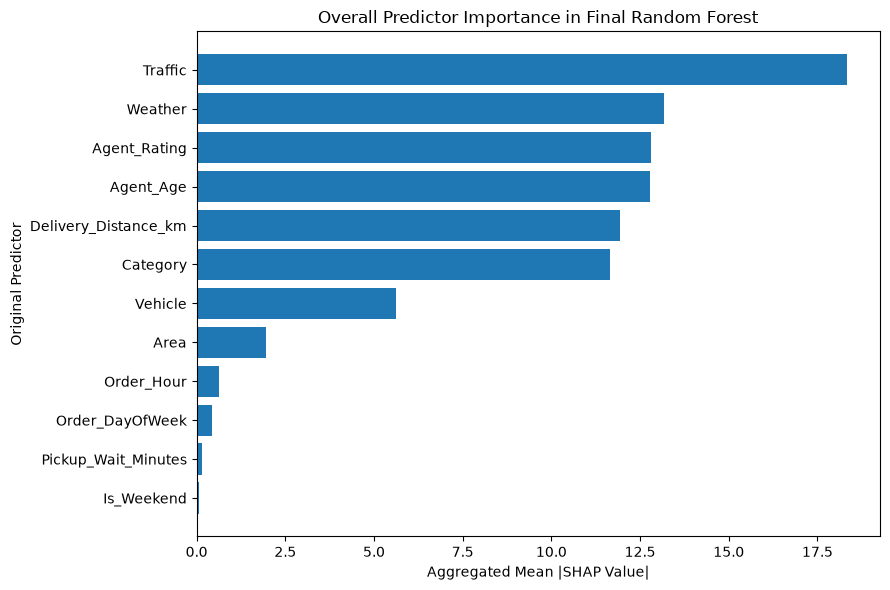

In [ ]:
aggregated_plot = (
    aggregated_shap
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=True
    )
)

plt.figure(figsize=(9, 6))

plt.barh(
    aggregated_plot["Original_Feature"],
    aggregated_plot["Mean_Absolute_SHAP"]
)

plt.xlabel("Aggregated Mean |SHAP Value|")
plt.ylabel("Original Predictor")
plt.title(
    "Overall Predictor Importance in Final Random Forest"
)

plt.tight_layout()
plt.show()

### 16.4 Individual High-Risk Delivery Explanation

Global SHAP analysis explains which predictors influence the model overall, but operational decision-making may require understanding why a specific delivery received a high predicted delivery time.

To demonstrate local explainability, the test delivery with the highest predicted delivery time is selected.

SHAP is then used to identify which individual feature values pushed that prediction higher or lower relative to the model's average prediction.

This provides an example of how the predictive model could support investigation of individual high-risk deliveries.

In [ ]:
# ============================================================
# 16.4 INDIVIDUAL HIGH-RISK DELIVERY EXPLANATION
# ============================================================

# Position of highest predicted delivery time
high_risk_position = np.argmax(final_predictions)

# Original test observation
high_risk_raw = X_test.iloc[[high_risk_position]]

# Actual and predicted delivery time
high_risk_actual = y_test.iloc[high_risk_position]

high_risk_prediction = (
    final_predictions[high_risk_position]
)

high_risk_level = assign_delivery_risk(
    high_risk_prediction
)

print("SELECTED HIGH-RISK DELIVERY")
print("=" * 60)

print(
    f"Actual delivery time    : "
    f"{high_risk_actual:.2f} minutes"
)

print(
    f"Predicted delivery time : "
    f"{high_risk_prediction:.2f} minutes"
)

print(
    f"Relative risk level     : "
    f"{high_risk_level}"
)

SELECTED HIGH-RISK DELIVERY
Actual delivery time    : 265.00 minutes
Predicted delivery time : 255.29 minutes
Relative risk level     : High Risk


In [ ]:
display(
    high_risk_raw.T.rename(
        columns={
            high_risk_raw.index[0]:
            "Delivery Details"
        }
    )
)

,Delivery Details
Agent_Age,31
Agent_Rating,4.2
Delivery_Distance_km,10.881078
Pickup_Wait_Minutes,5
Order_Hour,19
Is_Weekend,1
Weather,Stormy
Traffic,Jam
Vehicle,motorcycle
Area,Semi-Urban


In [ ]:
# Transform the selected observation

high_risk_processed = (
    final_preprocessor.transform(
        high_risk_raw
    )
)

high_risk_processed_df = pd.DataFrame(
    high_risk_processed,
    columns=shap_feature_names,
    index=high_risk_raw.index
)

# Calculate SHAP explanation
high_risk_shap = shap_explainer(
    high_risk_processed_df
)

print(
    "Individual SHAP explanation "
    "calculated successfully!"
)

Individual SHAP explanation calculated successfully!


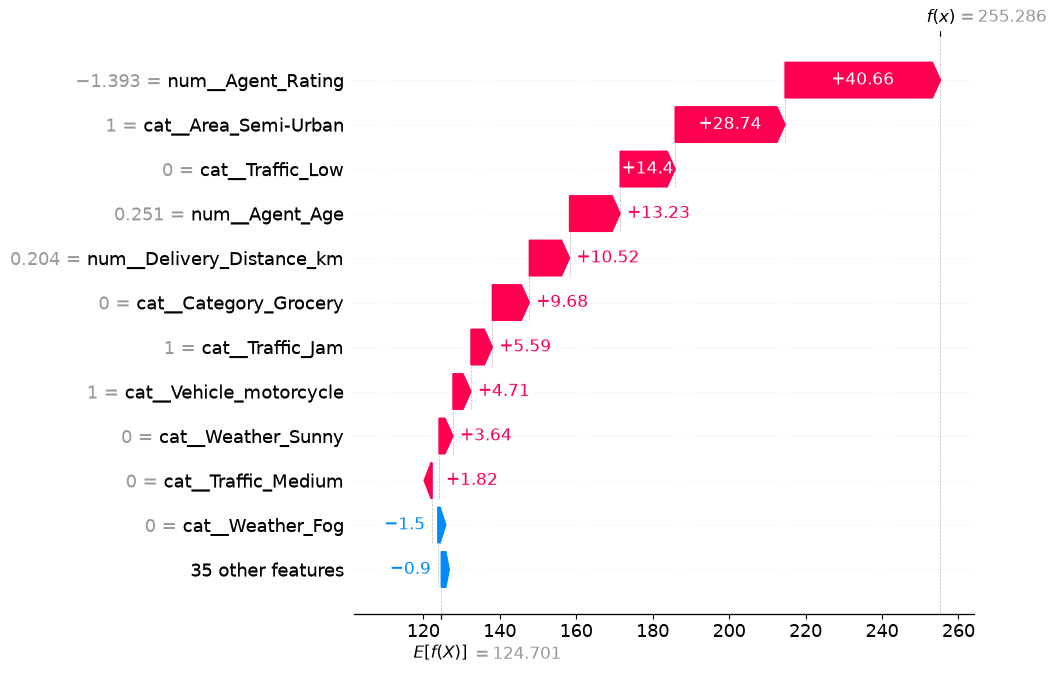

In [ ]:
# SHAP waterfall plot for selected high-risk delivery

shap.plots.waterfall(
    high_risk_shap[0],
    max_display=12
)

#### Individual High-Risk Delivery Interpretation

The selected high-risk delivery had an actual delivery time of 265 minutes and a predicted delivery time of 255.29 minutes.

The model's average expected prediction was approximately 124.70 minutes. SHAP analysis showed that several factors pushed this individual prediction substantially higher.

The largest positive contribution came from the agent rating of 4.2, which increased the prediction by approximately 40.66 minutes relative to the model baseline.

The Semi-Urban delivery area contributed approximately 28.74 additional minutes. Traffic-related conditions also played an important role: the absence of low traffic and the presence of traffic jam conditions both increased the predicted delivery time.

Other positive contributors included the agent's age of 31 years, a delivery distance of approximately 10.88 km, motorcycle use, and the order not belonging to the Grocery category.

Together, these effects increased the model prediction from its baseline expectation of approximately 124.70 minutes to 255.29 minutes.

The actual delivery duration was 265 minutes, indicating that the model identified this observation as a relatively high-risk delivery with an absolute prediction error of approximately 9.71 minutes.

This example demonstrates how SHAP can provide an interpretable explanation for an individual prediction rather than presenting only a risk label or predicted delivery time.

In [ ]:
individual_shap_table = pd.DataFrame({
    "Feature": shap_feature_names,
    "SHAP_Contribution": (
        high_risk_shap.values[0]
    ),
    "Feature_Value": (
        high_risk_processed_df.iloc[0].values
    )
})

individual_shap_table[
    "Absolute_Impact"
] = np.abs(
    individual_shap_table[
        "SHAP_Contribution"
    ]
)

individual_shap_table = (
    individual_shap_table
    .sort_values(
        "Absolute_Impact",
        ascending=False
    )
    .reset_index(drop=True)
)

individual_shap_table["Feature"] = (
    individual_shap_table["Feature"]
    .str.replace(
        "num__",
        "",
        regex=False
    )
    .str.replace(
        "cat__",
        "",
        regex=False
    )
    .str.replace(
        "_",
        " "
    )
)

display(
    individual_shap_table[
        [
            "Feature",
            "Feature_Value",
            "SHAP_Contribution"
        ]
    ]
    .head(12)
    .round(3)
)

,Feature,Feature_Value,SHAP_Contribution
0,Agent Rating,-1.393,40.661
1,Area Semi-Urban,1.000,28.736
2,Traffic Low,0.000,14.402
3,Agent Age,0.251,13.234
4,Delivery Distance km,0.204,10.519
5,Category Grocery,0.000,9.679
6,Traffic Jam,1.000,5.588
7,Vehicle motorcycle,1.000,4.711
8,Weather Sunny,0.000,3.643
9,Traffic Medium,0.000,1.817
